# YOLOv8+LSTM Model for Dashcam Crash Prediction

**Nexar Dashcam Collision Prediction**

**Architecture**: YOLOv8n backbone (scene features) + Attention-based Detection Encoder (object-level features)  LSTM temporal aggregator  Driver Safety Score  
**Input**: `(B, T, C, H, W)` video clips + `(B, T, K, 6)` per-frame detection features  
**Expected**: 9193% accuracy * 24 FPS * ~80 MB  
**Protocol**: 3-fold Stratified CV * `nn.DataParallel` on Kaggle T4 -- 2 * shared splits with CNN-LSTM baseline

---
**Run order**: CNN-LSTM must run first to create `shared_data_splits.json`. Place it in `/kaggle/working/` before running this notebook.

In [1]:
!cp /kaggle/input/datasets/kashyap077/data-split/shared_data_splits.json /kaggle/working/

## 1. Environment Setup & Dependencies

In [2]:
%%capture
!pip install decord --quiet
!pip install scikit-learn --quiet
!pip install tqdm --quiet
!pip install matplotlib seaborn --quiet
!pip install ultralytics --quiet


In [3]:
import os, sys, json, math, time, random, warnings, datetime
from pathlib import Path
from copy import deepcopy
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torch.cuda.amp import GradScaler, autocast
import torch.distributed as dist, torch.multiprocessing as mp
from torch.nn.parallel import DistributedDataParallel as DDP

from torchvision import transforms, models
from PIL import Image
from ultralytics import YOLO

from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, roc_curve,
    precision_recall_curve, confusion_matrix)

from decord import VideoReader, cpu, gpu

warnings.filterwarnings('ignore')
print(f'PyTorch: {torch.__version__}')
print(f'CUDA: {torch.cuda.is_available()}, GPUs: {torch.cuda.device_count()}')
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        print(f'  GPU {i}: {torch.cuda.get_device_name(i)}, '
              f'{torch.cuda.get_device_properties(i).total_memory/1e9:.1f} GB')


Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
PyTorch: 2.10.0+cu128
CUDA: True, GPUs: 2
  GPU 0: Tesla T4, 15.6 GB
  GPU 1: Tesla T4, 15.6 GB


## 2. Configuration

In [4]:
!rm -rf /kaggle/working/*
import shutil, glob

for d in ['/kaggle/working/checkpoints', '/kaggle/working/results/yolov8_lstm',
          '/kaggle/working/frame_cache', '/kaggle/working/det_cache']:
    os.makedirs(d, exist_ok=True)

for f in glob.glob('/kaggle/input/**/*.pth', recursive=True):
    shutil.copy(f, '/kaggle/working/checkpoints/'); print(f'Copied: {f}')
for f in glob.glob('/kaggle/input/**/shared_data_splits.json', recursive=True):
    shutil.copy(f, '/kaggle/working/'); print(f'Copied splits: {f}')
print('Staging done.')


Copied splits: /kaggle/input/datasets/kashyap077/data-split/shared_data_splits.json
Staging done.


In [5]:
CONFIG = {
    # Paths
    'data_root':         '/kaggle/input/competitions/nexar-collision-prediction',
    'train_video_dir':   '/kaggle/input/competitions/nexar-collision-prediction/train',
    'test_video_dir':    '/kaggle/input/competitions/nexar-collision-prediction/test',
    'train_csv':         '/kaggle/input/competitions/nexar-collision-prediction/train.csv',
    'test_csv':          '/kaggle/input/competitions/nexar-collision-prediction/test.csv',
    'sample_submission': '/kaggle/input/competitions/nexar-collision-prediction/sample_submission.csv',
    'checkpoint_dir':    '/kaggle/working/checkpoints',
    'results_dir':       '/kaggle/working/results/yolov8_lstm',
    'shared_splits_path':'/kaggle/working/shared_data_splits.json',
    'frame_cache_dir':   '/kaggle/working/frame_cache',
    'det_cache_dir':     '/kaggle/working/det_cache',

    # Model identity
    'model_name': 'yolov8_lstm',

    # YOLOv8 backbone
    'yolo_weights':           'yolov8n.pt',
    'backbone_feat_dim':      256,
    'freeze_backbone':        True,
    'freeze_backbone_epochs': 5,

    # Detection branch
    'max_detections':      20,
    'det_input_dim':        6,
    'det_embed_dim':      128,
    'yolo_conf_threshold': 0.25,
    'yolo_iou_threshold':  0.45,
    'num_det_classes':     80,

    # LSTM
    'lstm_hidden_size': 512,
    'lstm_num_layers':    2,
    'lstm_dropout':     0.4,

    # Head
    'spatial_dropout': 0.3,
    'head_dropout':    0.5,
    'num_classes':       1,

    # Video (shared across ALL models  do NOT change)
    'sequence_length':    16,
    'sample_fps':          5,
    'img_size':          224,
    'crop_top_fraction': 0.15,

    # Training
    'seed': 42, 'split_seed': 42, 'n_folds': 3,
    'epochs': 20, 'batch_size': 16,
    'gradient_accumulation_steps': 2,
    'num_workers': 2, 'pin_memory': True,

    # Optimizer
    'lr_backbone': 1e-5, 'lr_temporal': 1e-4, 'lr_classifier': 1e-3,
    'weight_decay': 1e-4, 'grad_clip_max_norm': 1.0,

    # LR schedule
    'warmup_epochs': 5, 'warmup_start_factor': 0.1, 'min_lr': 1e-6,

    # Loss
    'focal_gamma': 2.0, 'focal_alpha': 0.75, 'label_smoothing': 0.1,
    'pre_crash_weight': 3.0, 'normal_weight': 1.0, 'post_crash_weight': 0.0,
    'pre_crash_window_sec': 3.0,

    # MixUp
    'mixup_alpha': 0.4, 'mixup_prob': 0.5,

    # Early stopping
    'patience': 8, 'monitor': 'val_auc',

    # Inference
    'inference_stride': 4, 'ema_alpha': 0.4, 'ema_init': 0.0,

    # Safety score
    'safety_score_weight': 1.0,

    # TTA
    'tta_num_views': 5, 'tta_temporal_jitter_frac': 0.1,

    # Calibration
    'ece_bins': 15,

    # Augmentation
    'aug_hflip_p': 0.5, 'aug_crop_scale': (0.8, 1.0), 'aug_crop_ratio': (0.9, 1.1),
    'aug_brightness': 0.25, 'aug_contrast': 0.25, 'aug_saturation': 0.3, 'aug_hue': 0.05,
    'aug_gamma_range': (0.6, 1.4), 'aug_grayscale_p': 0.05,
    'aug_blur_sigma': (0.1, 2.0), 'aug_blur_kernel': 5,
    'aug_noise_sigma': (0.01, 0.05), 'aug_temporal_jitter': 2,

    # Data split
    'holdout_test_size': 450, 'holdout_test_fraction': 0.3,

    # Hardware
    'use_ddp': True, 'backend': 'nccl', 'use_amp': True,
    'deterministic': True, 'benchmark': False,
}

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print(f'Device: {DEVICE}')
print(f'Model: {CONFIG["model_name"]}')
print(f'YOLOv8 weights: {CONFIG["yolo_weights"]}')
print(f'Backbone feat dim: {CONFIG["backbone_feat_dim"]}')
print(f'Detection embed dim: {CONFIG["det_embed_dim"]}')
print(f'Fused dim: {CONFIG["backbone_feat_dim"] + CONFIG["det_embed_dim"]}')
print(f'LSTM: hidden={CONFIG["lstm_hidden_size"]}, layers={CONFIG["lstm_num_layers"]}')


Device: cuda
Model: yolov8_lstm
YOLOv8 weights: yolov8n.pt
Backbone feat dim: 256
Detection embed dim: 128
Fused dim: 384
LSTM: hidden=512, layers=2


## 3. Reproducibility & Utilities

In [6]:
def set_seed(seed: int):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = CONFIG['deterministic']
    torch.backends.cudnn.benchmark = CONFIG['benchmark']
    os.environ['PYTHONHASHSEED'] = str(seed)

def get_device(rank=0):
    return torch.device(f'cuda:{rank}' if torch.cuda.is_available() else 'cpu')

def count_parameters(model):
    total = sum(p.numel() for p in model.parameters())
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    return total, trainable

def model_size_mb(model):
    param_size = sum(p.numel() * p.element_size() for p in model.parameters())
    buf_size = sum(b.numel() * b.element_size() for b in model.buffers())
    return (param_size + buf_size) / 1e6

def unwrap_model(model):
    return model.module if hasattr(model, 'module') else model

set_seed(CONFIG['seed'])
print(f'Seed set to {CONFIG["seed"]}')


Seed set to 42


## 4. Data Loading & Shared Splits

Loads `shared_data_splits.json` created by CNN-LSTM. If not found, generates new splits from `train.csv` using the same protocol.  
All models **must** use the same 450-video test hold-out for valid comparisons.

In [7]:
train_df = pd.read_csv(CONFIG['train_csv'])
print(f'Loaded {len(train_df)} videos: {train_df["target"].sum()} crash, '
      f'{(train_df["target"]==0).sum()} normal')

# -- Use ALL available videos  --  no artificial cap ----------------------
# Class imbalance is handled by WeightedRandomSampler and focal loss,
# not by discarding data. More data = better generalisation.
crash_df  = train_df[train_df['target'] == 1]
normal_df = train_df[train_df['target'] == 0]
print(f'Using ALL data: {len(crash_df)} crash + {len(normal_df)} normal = {len(train_df)} total')
print(f'Class ratio crash/total: {len(crash_df)/len(train_df):.3f}')
train_df = train_df.sample(frac=1, random_state=CONFIG['seed']).reset_index(drop=True)


Loaded 1500 videos: 750 crash, 750 normal
Using ALL data: 750 crash + 750 normal = 1500 total
Class ratio crash/total: 0.500


In [8]:
def generate_shared_splits(df, config):
    splits_path = config['shared_splits_path']
    if os.path.exists(splits_path):
        print(f'Loading existing splits from {splits_path}')
        with open(splits_path) as f:
            return json.load(f)
    print('shared_data_splits.json not found  generating new splits.')
    ids, targets = df['id'].values, df['target'].values
    from sklearn.model_selection import train_test_split, StratifiedKFold
    trainval_ids, test_ids, trainval_targets, _ = train_test_split(
        ids, targets, test_size=config['holdout_test_fraction'],
        stratify=targets, random_state=config['split_seed'])
    skf = StratifiedKFold(n_splits=config['n_folds'], shuffle=True, random_state=config['split_seed'])
    folds = {}
    for fold_idx, (tr_idx, val_idx) in enumerate(skf.split(trainval_ids, trainval_targets)):
        folds[str(fold_idx)] = {
            'train_ids': trainval_ids[tr_idx].tolist(),
            'val_ids':   trainval_ids[val_idx].tolist()}
    splits = {'test_ids': test_ids.tolist(), 'trainval_ids': trainval_ids.tolist(), 'folds': folds}
    with open(splits_path, 'w') as f:
        json.dump(splits, f, indent=2)
    print(f'Saved splits  {splits_path}')
    print(f'  Test: {len(test_ids)} | TrainVal: {len(trainval_ids)} | Folds: {config["n_folds"]}')
    return splits

splits = generate_shared_splits(train_df, CONFIG)
print(f'Test IDs: {len(splits["test_ids"])} | '
      f'Fold 0 train: {len(splits["folds"]["0"]["train_ids"])} | '
      f'Fold 0 val: {len(splits["folds"]["0"]["val_ids"])}')


Loading existing splits from /kaggle/working/shared_data_splits.json
Test IDs: 90 | Fold 0 train: 140 | Fold 0 val: 70


In [9]:
import datetime
config_out = {k: str(v) if not isinstance(v, (int, float, bool, str, list)) else v
              for k, v in CONFIG.items()}
config_out['timestamp'] = datetime.datetime.now().isoformat()
with open(os.path.join(CONFIG['results_dir'], 'config.json'), 'w') as f:
    json.dump(config_out, f, indent=2)
print('Config saved to results dir.')


Config saved to results dir.


## 5. Video Loading with Decord

All video I/O uses `decord` for fast GPU-accelerated decoding.  
Preprocessing pipeline (shared across all 7 models):  
- Sample at `sample_fps=5`  16-frame clips  
- Crop top 15% (dashcam watermark)  
- Resize to 224 -- 224  
- Normalize with ImageNet mean/std

In [10]:
def load_video_decord(video_path, sample_fps=5):
    try:
        vr = VideoReader(video_path, ctx=cpu(0))
    except Exception:
        vr = VideoReader(video_path, ctx=cpu(0))
    video_fps = vr.get_avg_fps()
    total_frames = len(vr)
    if video_fps <= 0: video_fps = 30.0
    step = max(1, round(video_fps / sample_fps))
    indices = list(range(0, total_frames, step))
    frames = vr.get_batch(indices).asnumpy()
    return frames, video_fps

def crop_top(frames, crop_frac):
    if isinstance(frames, np.ndarray):
        h = frames.shape[1]
        crop_h = int(h * crop_frac)
        return frames[:, crop_h:, :, :]
    h = frames.shape[0]
    crop_h = int(h * crop_frac)
    return frames[crop_h:, :, :]

print('Video loading utilities defined.')


Video loading utilities defined.


## 6. Augmentation Pipeline

In [11]:
class RandomGammaCorrection:
    def __init__(self, gamma_range=(0.6, 1.4)): self.gamma_range = gamma_range
    def __call__(self, img):
        gamma = random.uniform(*self.gamma_range)
        return torch.clamp(img.pow(gamma), 0.0, 1.0)

class GaussianNoise:
    def __init__(self, sigma_range=(0.01, 0.05)): self.sigma_range = sigma_range
    def __call__(self, img):
        sigma = random.uniform(*self.sigma_range)
        return img + torch.randn_like(img) * sigma

def get_train_spatial_transform(config):
    return transforms.Compose([
        transforms.Resize((int(config['img_size']*1.15), int(config['img_size']*1.15))),
        transforms.RandomCrop(config['img_size']),
        transforms.RandomHorizontalFlip(p=config['aug_hflip_p']),
        transforms.ColorJitter(
            brightness=config['aug_brightness'], contrast=config['aug_contrast'],
            saturation=config['aug_saturation'], hue=config['aug_hue']),
        transforms.RandomGrayscale(p=config['aug_grayscale_p']),
        transforms.GaussianBlur(kernel_size=config['aug_blur_kernel'],
                                sigma=config['aug_blur_sigma']),
        transforms.ToTensor(),
        RandomGammaCorrection(config['aug_gamma_range']),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

normalize_transform = transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD)

def get_val_transform(config):
    return transforms.Compose([
        transforms.Resize((config['img_size'], config['img_size'])),
        transforms.ToTensor(),
        transforms.Normalize(mean=IMAGENET_MEAN, std=IMAGENET_STD),
    ])

print('Augmentation pipeline defined.')


Augmentation pipeline defined.


## 7. Preprocessing  Frame & Detection Cache

**Two-stage one-time preprocessing (run once, reuse across sessions):**

1. **Frame cache**  decode each `.mp4` at 5 FPS  crop  resize  save JPEGs  
2. **Detection cache**  run YOLOv8n on every cached frame  save top-20 detections per frame as `.npy`

Both caches are keyed by `video_id`. Subsequent epochs load from disk  no video decoding overhead.

In [12]:
def extract_frames_to_cache(video_dir, video_ids, config):
    cache_dir  = config['frame_cache_dir']
    img_size   = config['img_size']
    crop_frac  = config['crop_top_fraction']
    sample_fps = config['sample_fps']
    os.makedirs(cache_dir, exist_ok=True)
    already, newly = 0, 0
    for vid in tqdm(video_ids, desc='Caching frames'):
        vid_dir   = os.path.join(cache_dir, str(int(vid)))
        meta_path = os.path.join(vid_dir, 'meta.json')
        if os.path.exists(meta_path): already += 1; continue
        video_path = os.path.join(video_dir, f'{int(vid):05d}.mp4')
        if not os.path.exists(video_path): continue
        try:
            vr = VideoReader(video_path, ctx=cpu(0))
            video_fps = vr.get_avg_fps() or 30.0
            step = max(1, round(video_fps / sample_fps))
            indices = list(range(0, len(vr), step))
            frames = vr.get_batch(indices).asnumpy()  # (N,H,W,C)
            del vr
        except Exception as e:
            print(f'Frame cache error {vid}: {e}'); continue
        frames = crop_top(frames, crop_frac)
        os.makedirs(vid_dir, exist_ok=True)
        for i, frame in enumerate(frames):
            img = Image.fromarray(frame).resize((img_size, img_size), Image.BILINEAR)
            img.save(os.path.join(vid_dir, f'frame_{i:04d}.jpg'), quality=92)
        with open(meta_path, 'w') as f:
            json.dump({'n_frames': len(frames), 'sample_fps': sample_fps}, f)
        newly += 1
    print(f'Frame cache: {newly} new, {already} already cached.')

print('extract_frames_to_cache defined.')


extract_frames_to_cache defined.


In [13]:
def extract_detections_to_cache(video_ids, config, yolo_model=None):
    """
    Pre-extract YOLOv8 detections for all cached frames.
    Saves: {det_cache_dir}/{video_id}/detections.npy  shape=(N_frames, K, 6)
    Feature layout per detection: [x1_norm, y1_norm, x2_norm, y2_norm, conf, cls_norm]
    Padded with zeros when fewer than K detections found.
    """
    det_dir    = config['det_cache_dir']
    frame_dir  = config['frame_cache_dir']
    K          = config['max_detections']
    conf_thr   = config['yolo_conf_threshold']
    iou_thr    = config['yolo_iou_threshold']
    num_cls    = config['num_det_classes']
    os.makedirs(det_dir, exist_ok=True)

    if yolo_model is None:
        print('Loading YOLOv8n for detection caching...')
        yolo_model = YOLO(config['yolo_weights'])

    already, newly = 0, 0
    for vid in tqdm(video_ids, desc='Caching detections'):
        vid_det_dir  = os.path.join(det_dir, str(int(vid)))
        det_npy_path = os.path.join(vid_det_dir, 'detections.npy')
        meta_path    = os.path.join(vid_det_dir, 'det_meta.json')
        if os.path.exists(meta_path) and os.path.exists(det_npy_path):
            already += 1; continue

        vid_frame_dir = os.path.join(frame_dir, str(int(vid)))
        if not os.path.isdir(vid_frame_dir): continue
        frame_files = sorted([f for f in os.listdir(vid_frame_dir) if f.endswith('.jpg')])
        n_frames = len(frame_files)
        if n_frames == 0: continue

        os.makedirs(vid_det_dir, exist_ok=True)
        all_dets = np.zeros((n_frames, K, 6), dtype=np.float32)
        frame_paths = [os.path.join(vid_frame_dir, f) for f in frame_files]

        # Process in batches of 8
        for b_start in range(0, n_frames, 8):
            batch_paths = frame_paths[b_start:b_start + 8]
            try:
                results = yolo_model.predict(batch_paths, verbose=False,
                                             conf=conf_thr, iou=iou_thr)
            except Exception as e:
                print(f'YOLOv8 predict error vid={vid}: {e}'); continue
            for i, result in enumerate(results):
                frame_idx = b_start + i
                boxes = result.boxes
                if boxes is None or len(boxes) == 0: continue
                xyxy_n    = boxes.xyxyn.cpu().numpy()          # (N,4) normalized
                conf_vals = boxes.conf.cpu().numpy()            # (N,)
                cls_vals  = boxes.cls.cpu().numpy() / num_cls   # normalize to [0,1]
                order = np.argsort(-conf_vals)
                xyxy_n, conf_vals, cls_vals = xyxy_n[order], conf_vals[order], cls_vals[order]
                n_valid = min(len(conf_vals), K)
                all_dets[frame_idx, :n_valid, :4] = xyxy_n[:n_valid]
                all_dets[frame_idx, :n_valid,  4] = conf_vals[:n_valid]
                all_dets[frame_idx, :n_valid,  5] = cls_vals[:n_valid]

        np.save(det_npy_path, all_dets)
        with open(meta_path, 'w') as f:
            json.dump({'n_frames': n_frames}, f)
        newly += 1

    print(f'Detection cache: {newly} new, {already} already cached.')
    return yolo_model

print('extract_detections_to_cache defined.')


extract_detections_to_cache defined.


In [14]:
# Run preprocessing  frame extraction then detection caching
all_video_ids = train_df['id'].tolist()

print('=== Stage 1: Frame extraction ===')
extract_frames_to_cache(CONFIG['train_video_dir'], all_video_ids, CONFIG)

print('\n=== Stage 2: Detection cache (YOLOv8n) ===')
yolo_cache_model = extract_detections_to_cache(all_video_ids, CONFIG)
# Keep yolo_cache_model in memory  reused for online detection in streaming demo
print('\nPreprocessing complete.')


=== Stage 1: Frame extraction ===


Caching frames:   0%|          | 0/1500 [00:00<?, ?it/s]

Frame cache: 1500 new, 0 already cached.

=== Stage 2: Detection cache (YOLOv8n) ===
Loading YOLOv8n for detection caching...


Caching detections:   0%|          | 0/1500 [00:00<?, ?it/s]

Detection cache: 1500 new, 0 already cached.

Preprocessing complete.


## 8. Dataset Classes

`YOLOv8CrashVideoDataset` extends the MIL-based sliding-window dataset from CNN-LSTM to also return per-frame detection features loaded from the detection cache.

Returns per sample: `(clips, det_feats, det_masks, label, weight)`  
- `clips`: `(T, C, H, W)`  video frames  
- `det_feats`: `(T, K, 6)`  detection features  
- `det_masks`: `(T, K)` bool  True for valid (non-padded) detections  
- `label`: int  0 or 1  
- `weight`: float  temporal importance weight

In [15]:
class YOLOv8CrashVideoDataset(Dataset):
    """
    MIL-based dataset for YOLOv8+LSTM crash prediction.
    Loads pre-extracted JPEG frames + YOLOv8 detection cache.
    Each video is sliced into overlapping 16-frame chunks.
    """
    def __init__(self, video_ids, df, video_dir, config,
                 is_train=True, spatial_transform=None):
        self.df = df[df['id'].isin(video_ids)].reset_index(drop=True)
        self.config = config
        self.is_train = is_train
        self.transform = spatial_transform
        self.val_transform = get_val_transform(config)
        self.noise_aug = GaussianNoise(config['aug_noise_sigma']) if is_train else None
        self.frame_cache = config['frame_cache_dir']
        self.det_cache   = config['det_cache_dir']
        self.K  = config['max_detections']
        self.chunks = []
        self._precompute_chunks()

    def _precompute_chunks(self):
        seq_len = self.config['sequence_length']
        stride  = max(1, seq_len // 2)
        sample_fps = self.config['sample_fps']
        pre_win    = self.config['pre_crash_window_sec']
        for _, row in tqdm(self.df.iterrows(), total=len(self.df),
                           desc='Pre-computing chunks', leave=False):
            vid   = int(row['id'])
            label = int(row['target'])
            toe   = row.get('time_of_event', None)
            vid_dir   = os.path.join(self.frame_cache, str(vid))
            meta_path = os.path.join(vid_dir, 'meta.json')
            if os.path.exists(meta_path):
                with open(meta_path) as f: n_frames = json.load(f).get('n_frames', 0)
            elif os.path.isdir(vid_dir):
                n_frames = len([x for x in os.listdir(vid_dir) if x.endswith('.jpg')])
            else:
                n_frames = 0
            if n_frames == 0: continue
            if n_frames < seq_len:
                self.chunks.append((vid, label, 0, n_frames, 1.0)); continue
            # Build all window starts, always including the tail anchor so
            # the final frames of the video are never missed.
            all_starts = list(range(0, n_frames - seq_len + 1, stride))
            tail_start = n_frames - seq_len
            if all_starts and all_starts[-1] != tail_start:
                all_starts.append(tail_start)   # plug the tail gap
            for start in all_starts:
                end = start + seq_len
                weight = 1.0
                if label == 1 and toe is not None:
                    try:
                        ef = float(toe) * sample_fps
                        if start <= ef < end:
                            # Chunk spans the crash moment - highest learning signal
                            weight = self.config['pre_crash_weight']
                        elif end <= ef and (ef - end) / sample_fps <= pre_win:
                            # Chunk ends just before crash - high pre-crash context
                            weight = self.config['pre_crash_weight']
                        elif start >= ef:
                            # Chunk is entirely after the crash - skip.
                            # Post-crash footage (stopped car, debris) would teach
                            # the model to predict crash=1 from wrong visual cues.
                            weight = self.config['post_crash_weight']
                    except (ValueError, TypeError): pass
                if weight == 0.0:
                    continue  # Skip zero-weight post-crash chunks
                self.chunks.append((vid, label, start, end, weight))

    def get_class_weights_for_sampler(self):
        labels = np.array([c[1] for c in self.chunks])
        class_counts = np.bincount(labels)
        class_weights = 1.0 / (class_counts + 1e-6)
        sample_weights = torch.tensor([class_weights[l] for l in labels], dtype=torch.float32)
        return sample_weights

    def _load_frames(self, vid, start, end):
        seq_len = self.config['sequence_length']
        vid_dir = os.path.join(self.frame_cache, str(vid))
        frames = []
        for idx in range(start, end):
            fp = os.path.join(vid_dir, f'frame_{idx:04d}.jpg')
            if os.path.exists(fp):
                frames.append(Image.open(fp).convert('RGB'))
        while len(frames) < seq_len:
            frames.append(frames[-1] if frames else
                          Image.new('RGB', (self.config['img_size'], self.config['img_size'])))
        return frames[:seq_len]

    def _load_detections(self, vid, start, end):
        seq_len = self.config['sequence_length']
        K = self.K
        det_path = os.path.join(self.det_cache, str(vid), 'detections.npy')
        if os.path.exists(det_path):
            all_dets = np.load(det_path)  # (N_frames, K, 6)
            N = all_dets.shape[0]
            dets = []
            for idx in range(start, end):
                dets.append(all_dets[idx] if idx < N else np.zeros((K, 6), np.float32))
            while len(dets) < seq_len:
                dets.append(dets[-1] if dets else np.zeros((K, 6), np.float32))
            det_array = np.stack(dets[:seq_len], axis=0)  # (T, K, 6)
        else:
            det_array = np.zeros((seq_len, K, 6), np.float32)
        mask = det_array[:, :, 4] > 0  # (T, K) valid where conf>0
        return torch.from_numpy(det_array).float(), torch.from_numpy(mask)

    def __len__(self): return len(self.chunks)

    def __getitem__(self, idx):
        vid, label, start, end, weight = self.chunks[idx]
        frames = self._load_frames(vid, start, end)
        t = self.transform if (self.is_train and self.transform) else self.val_transform
        processed = []
        for frame in frames:
            tensor = t(frame)
            if self.is_train and self.noise_aug:
                tensor = self.noise_aug(tensor)
            processed.append(tensor)
        clips = torch.stack(processed, dim=0)  # (T,C,H,W)
        det_feats, det_masks = self._load_detections(vid, start, end)
        return (clips, det_feats, det_masks,
                torch.tensor(label, dtype=torch.long),
                torch.tensor(weight, dtype=torch.float32))

print('YOLOv8CrashVideoDataset defined.')


YOLOv8CrashVideoDataset defined.


In [16]:
class SlidingWindowInferenceDataset(Dataset):
    """
    Sliding-window dataset for test-time inference.
    Loads frames from frame cache + detections from det cache (if available).
    """
    def __init__(self, video_path, config):
        self.config = config
        self.seq_len = config['sequence_length']
        self.K = config['max_detections']
        self.transform = get_val_transform(config)
        frames_raw, _ = load_video_decord(video_path, config['sample_fps'])
        frames_raw = crop_top(frames_raw, config['crop_top_fraction'])
        self.frames_pil = [
            Image.fromarray(f).resize((config['img_size'], config['img_size']), Image.BILINEAR)
            for f in frames_raw]
        self.n_frames = len(self.frames_pil)
        stride = config['inference_stride']
        # Build evenly-strided windows, then always append a tail window
        # anchored at n_frames - seq_len so the last frames are never skipped.
        starts = list(range(0, max(1, self.n_frames - self.seq_len + 1), stride))
        if self.n_frames >= self.seq_len:
            tail_s = self.n_frames - self.seq_len
            if not starts or starts[-1] != tail_s:
                starts.append(tail_s)   # plug the tail gap
        self.windows = [(s, s + self.seq_len) for s in starts]
        if not self.windows: self.windows = [(0, self.seq_len)]
        self.det_array = None  # loaded on-the-fly if cache available

    def __len__(self): return len(self.windows)

    def __getitem__(self, idx):
        start, end = self.windows[idx]
        frames = []
        for i in range(start, end):
            fr = self.frames_pil[min(i, self.n_frames-1)]
            frames.append(self.transform(fr))
        while len(frames) < self.seq_len:
            frames.append(frames[-1])
        clips = torch.stack(frames[:self.seq_len], dim=0)
        # Zero detections  model handles missing dets via empty_embed
        det_feats = torch.zeros(self.seq_len, self.K, 6)
        det_masks = torch.zeros(self.seq_len, self.K, dtype=torch.bool)
        return clips, det_feats, det_masks, torch.tensor(start)

print('SlidingWindowInferenceDataset defined.')


SlidingWindowInferenceDataset defined.


## 9. YOLOv8+LSTM Model Architecture

Three components:

1. **`YOLOv8BackboneExtractor`**  YOLOv8n backbone (layers 09, all sequential). Outputs `(B, 256)` via GlobalAvgPool. Supports frozen/unfrozen training.
2. **`DetectionEncoder`**  Attention-based aggregation of K detection slots  `(B, 128)`. Uses a learnable `empty_embed` for frames with no detections.
3. **`YOLOv8LSTM`**  Fuses both features per frame  `(B, T, 384)`  LSTM  classifier.

In [17]:
class YOLOv8BackboneExtractor(nn.Module):
    """
    YOLOv8n backbone as a feature extractor.
    Layers 0-9 (Conv  C2f  ...  SPPF) are all sequential in YOLOv8n  no
    cross-layer skip connections until the neck (layer 10+).
    Output: (B, 256) via GlobalAvgPool on the 7 -- 7 SPPF feature map.
    """
    def __init__(self, weights='yolov8n.pt', freeze=True):
        super().__init__()
        yolo = YOLO(weights)
        # Backbone: first 10 layers (indices 0-9)
        self.backbone = nn.Sequential(*list(yolo.model.model[:10]))
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.out_dim = 256  # YOLOv8n SPPF output channels
        del yolo  # free neck/head weights
        self._is_frozen = freeze
        if freeze: self._freeze()

    def _freeze(self):
        for p in self.backbone.parameters(): p.requires_grad_(False)
        self._is_frozen = True

    def unfreeze(self):
        for p in self.backbone.parameters(): p.requires_grad_(True)
        self._is_frozen = False
        print('  YOLOv8 backbone unfrozen.')

    def forward(self, x):
        feat = self.backbone(x)           # (B, 256, 7, 7) for 224 -- 224 input
        return self.pool(feat).flatten(1) # (B, 256)

print('YOLOv8BackboneExtractor defined.')


YOLOv8BackboneExtractor defined.


In [18]:
class DetectionEncoder(nn.Module):
    """
    Encode K per-frame detections into a fixed-size vector using attention pooling.

    Input:  dets  (B, K, 6)  [x1_n, y1_n, x2_n, y2_n, conf, cls_norm]
            mask  (B, K)     True for valid detections
    Output: (B, embed_dim)
    """
    def __init__(self, input_dim=6, embed_dim=128, max_dets=20):
        super().__init__()
        self.proj = nn.Sequential(
            nn.Linear(input_dim, 64), nn.GELU(),
            nn.Linear(64, embed_dim),
        )
        self.attn = nn.Linear(embed_dim, 1)
        # Learnable embedding for frames with zero valid detections
        self.empty_embed = nn.Parameter(torch.zeros(embed_dim))
        nn.init.trunc_normal_(self.empty_embed, std=0.02)

    def forward(self, dets, mask):
        B, K, _ = dets.shape
        emb    = self.proj(dets)                     # (B, K, E)
        scores = self.attn(emb).squeeze(-1)          # (B, K)
        scores = scores.masked_fill(~mask, float('-inf'))
        no_det = (~mask).all(dim=1)                  # (B,) frames with no detection
        # Avoid NaN softmax on all-masked rows
        safe_scores = scores.clone()
        safe_scores[no_det] = 0.0
        weights = F.softmax(safe_scores, dim=1).unsqueeze(-1)  # (B, K, 1)
        out = (emb * weights).sum(dim=1)             # (B, E)
        # Replace no-detection frames with empty_embed
        if no_det.any():
            out[no_det] = self.empty_embed.unsqueeze(0).expand(no_det.sum(), -1)
        return out

print('DetectionEncoder defined.')


DetectionEncoder defined.


In [19]:
class YOLOv8LSTM(nn.Module):
    """
    YOLOv8+LSTM model for dashcam crash prediction.

    Architecture per frame:
        YOLOv8n backbone  GAP  (256,) scene features
        DetectionEncoder (attention)  (128,) object features
        Concat  (384,) fused frame features

    Temporal aggregation:
        (B, T, 384)  LSTM(512, 2 layers)  last hidden (B, 512)

    Classifier:
        Dropout  Linear(512,256)  GELU  Dropout  Linear(256,1)

    Input:
        clips     : (B, T, C, H, W)
        det_feats : (B, T, K, 6)
        det_masks : (B, T, K)  bool
    Output: (B, 1) crash logit
    """
    def __init__(self, config):
        super().__init__()
        self.config = config

        #  YOLOv8 Backbone 
        self.backbone = YOLOv8BackboneExtractor(
            weights=config['yolo_weights'], freeze=config['freeze_backbone'])
        self.backbone_proj = nn.Sequential(
            nn.LayerNorm(self.backbone.out_dim),
            nn.Linear(self.backbone.out_dim, self.backbone.out_dim),
            nn.GELU())
        self.spatial_dropout = nn.Dropout(p=config['spatial_dropout'])

        #  Detection Encoder 
        self.det_encoder = DetectionEncoder(
            input_dim=config['det_input_dim'],
            embed_dim=config['det_embed_dim'],
            max_dets=config['max_detections'])

        #  LSTM 
        fused_dim = self.backbone.out_dim + config['det_embed_dim']  # 384
        self.lstm = nn.LSTM(
            input_size=fused_dim,
            hidden_size=config['lstm_hidden_size'],
            num_layers=config['lstm_num_layers'],
            batch_first=True,
            dropout=config['lstm_dropout'] if config['lstm_num_layers'] > 1 else 0.0)

        #  Classifier Head 
        self.head = nn.Sequential(
            nn.Dropout(p=config['head_dropout']),
            nn.Linear(config['lstm_hidden_size'], 256),
            nn.GELU(),
            nn.Dropout(p=config['head_dropout'] * 0.5),
            nn.Linear(256, config['num_classes']))

        self._init_weights()

    def _init_weights(self):
        for name, p in self.lstm.named_parameters():
            if 'weight_ih' in name or 'weight_hh' in name:
                nn.init.xavier_uniform_(p)
            elif 'bias' in name:
                nn.init.zeros_(p)
                n = p.size(0)
                p.data[n//4:n//2].fill_(1.0)  # forget gate bias = 1
        for m in [self.backbone_proj, self.head]:
            for layer in m.modules():
                if isinstance(layer, nn.Linear):
                    nn.init.xavier_uniform_(layer.weight)
                    if layer.bias is not None: nn.init.zeros_(layer.bias)

    def maybe_unfreeze_backbone(self, epoch):
        if (self.config['freeze_backbone'] and
                epoch >= self.config['freeze_backbone_epochs'] and
                self.backbone._is_frozen):
            self.backbone.unfreeze()

    def get_param_groups(self, config):
        backbone_params = list(self.backbone.parameters())
        temporal_params = list(self.det_encoder.parameters()) + list(self.lstm.parameters())
        head_params     = (list(self.backbone_proj.parameters()) +
                           list(self.head.parameters()))
        return [
            {'params': backbone_params, 'lr': config['lr_backbone']},
            {'params': temporal_params, 'lr': config['lr_temporal']},
            {'params': head_params,     'lr': config['lr_classifier']},
        ]

    def forward(self, clips, det_feats, det_masks):
        B, T, C, H, W = clips.shape
        K = det_feats.shape[2]
        # Scene features
        frames = clips.view(B * T, C, H, W)
        scene = self.backbone(frames)             # (B*T, 256)
        scene = self.backbone_proj(scene)          # (B*T, 256)
        scene = self.spatial_dropout(scene).view(B, T, -1)  # (B, T, 256)
        # Detection features
        dets  = det_feats.view(B * T, K, -1)
        masks = det_masks.view(B * T, K)
        obj   = self.det_encoder(dets, masks).view(B, T, -1)  # (B, T, 128)
        # Fuse & temporal
        fused = torch.cat([scene, obj], dim=-1)    # (B, T, 384)
        lstm_out, _ = self.lstm(fused)             # (B, T, 512)
        return self.head(lstm_out[:, -1, :])       # (B, 1)

print('YOLOv8LSTM model defined.')
# Quick shape check
_m = YOLOv8LSTM(CONFIG)
_x = torch.zeros(2, 4, 3, 224, 224)  # small T for speed
_d = torch.zeros(2, 4, 20, 6)
_k = torch.zeros(2, 4, 20, dtype=torch.bool)
with torch.no_grad(): _out = _m(_x, _d, _k)
print(f'Output shape: {_out.shape}  (expected: [2, 1])')
del _m, _x, _d, _k, _out


YOLOv8LSTM model defined.
Output shape: torch.Size([2, 1])  (expected: [2, 1])


## 10. Loss Functions

In [20]:
class FocalLossWithSmoothing(nn.Module):
    """
    Binary Focal Loss with label smoothing and per-sample weighting.
    FL(p_t) = -alpha_t * (1 - p_t)^gamma * log(p_t)
    Label smoothing: y_smooth = y*(1-eps) + 0.5*eps
    """
    def __init__(self, gamma=2.0, alpha=0.25, label_smoothing=0.1):
        super().__init__()
        self.gamma = gamma; self.alpha = alpha; self.ls = label_smoothing

    def forward(self, logits, targets, weights=None):
        targets_f = targets.float()
        targets_s = targets_f * (1 - self.ls) + 0.5 * self.ls
        bce = F.binary_cross_entropy_with_logits(
            logits.squeeze(-1), targets_s, reduction='none')
        p_t = torch.exp(-bce)
        alpha_t = self.alpha * targets_f + (1 - self.alpha) * (1 - targets_f)
        focal = alpha_t * (1 - p_t) ** self.gamma * bce
        if weights is not None: focal = focal * weights
        return focal.mean()

print('FocalLossWithSmoothing defined.')


FocalLossWithSmoothing defined.


## 11. Learning Rate Scheduler

3-epoch linear warmup  cosine annealing to `min_lr=1e-6`.

In [21]:
class WarmupCosineScheduler:
    def __init__(self, optimizer, warmup_epochs, total_epochs, min_lr, warmup_start_factor=0.1):
        self.optimizer = optimizer
        self.warmup_epochs = warmup_epochs
        self.total_epochs  = total_epochs
        self.min_lr = min_lr
        self.wsf = warmup_start_factor
        self.base_lrs = [g['lr'] for g in optimizer.param_groups]
        self.current_epoch = 0

    def step(self, epoch=None):
        self.current_epoch = epoch if epoch is not None else self.current_epoch + 1
        e = self.current_epoch
        for i, (g, base_lr) in enumerate(zip(self.optimizer.param_groups, self.base_lrs)):
            if e < self.warmup_epochs:
                factor = self.wsf + (1 - self.wsf) * e / max(1, self.warmup_epochs)
                g['lr'] = base_lr * factor
            else:
                prog = (e - self.warmup_epochs) / max(1, self.total_epochs - self.warmup_epochs)
                g['lr'] = self.min_lr + 0.5 * (base_lr - self.min_lr) * (1 + math.cos(math.pi * prog))

    def get_last_lr(self):
        return [g['lr'] for g in self.optimizer.param_groups]

print('WarmupCosineScheduler defined.')


WarmupCosineScheduler defined.


## 12. Training & Validation Functions

In [22]:
def temporal_mixup(clips, det_feats, det_masks, labels, weights, alpha=0.4):
    """Apply MixUp to clips + detection features simultaneously."""
    lam = np.random.beta(alpha, alpha)
    B = clips.size(0)
    idx = torch.randperm(B, device=clips.device)
    mixed_clips     = lam * clips     + (1 - lam) * clips[idx]
    mixed_dets      = lam * det_feats + (1 - lam) * det_feats[idx]
    mixed_masks     = det_masks | det_masks[idx]   # union of valid dets
    mixed_labels    = (lam * labels.float() + (1 - lam) * labels[idx].float()).long()
    mixed_weights   = lam * weights + (1 - lam) * weights[idx]
    return mixed_clips, mixed_dets, mixed_masks, mixed_labels, mixed_weights

print('temporal_mixup defined.')


temporal_mixup defined.


In [23]:
def train_one_epoch(model, dataloader, criterion, optimizer, scaler,
                    config, device, epoch, rank=0):
    model.train()
    running_loss = 0.0; all_preds = []; all_labels = []; n_batches = 0
    accum = config.get('gradient_accumulation_steps', 1)
    pbar  = tqdm(dataloader, desc=f'  Train Epoch {epoch+1}', leave=False, disable=(rank != 0))
    optimizer.zero_grad(set_to_none=True)
    for bi, (clips, det_feats, det_masks, labels, weights) in enumerate(pbar):
        clips     = clips.to(device, non_blocking=True)
        det_feats = det_feats.to(device, non_blocking=True)
        det_masks = det_masks.to(device, non_blocking=True)
        labels    = labels.to(device, non_blocking=True)
        weights   = weights.to(device, non_blocking=True)
        if random.random() < config['mixup_prob']:
            clips, det_feats, det_masks, labels, weights = temporal_mixup(
                clips, det_feats, det_masks, labels, weights, alpha=config['mixup_alpha'])
        with autocast(enabled=config['use_amp']):
            logits = model(clips, det_feats, det_masks)
            loss   = criterion(logits, labels, weights) / accum
        scaler.scale(loss).backward()
        if (bi + 1) % accum == 0 or (bi + 1) == len(dataloader):
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), config['grad_clip_max_norm'])
            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad(set_to_none=True)
        running_loss += loss.item() * accum; n_batches += 1
        with torch.no_grad():
            probs = torch.sigmoid(logits.squeeze(-1))
            preds = (probs > 0.5).long()
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
        if rank == 0:
            pbar.set_postfix({'loss': f'{running_loss/n_batches:.4f}'})
    acc = accuracy_score(all_labels, all_preds) if all_labels else 0.0
    return running_loss / max(n_batches, 1), acc

print('train_one_epoch defined.')


train_one_epoch defined.


In [24]:
@torch.no_grad()
def validate(model, dataloader, criterion, config, device, rank=0):
    model.eval()
    running_loss = 0.0; all_probs = []; all_labels = []; n_batches = 0
    for clips, det_feats, det_masks, labels, weights in tqdm(
            dataloader, desc='  Validate', leave=False, disable=(rank != 0)):
        clips     = clips.to(device, non_blocking=True)
        det_feats = det_feats.to(device, non_blocking=True)
        det_masks = det_masks.to(device, non_blocking=True)
        labels    = labels.to(device, non_blocking=True)
        weights   = weights.to(device, non_blocking=True)
        with autocast(enabled=config['use_amp']):
            logits = model(clips, det_feats, det_masks)
            loss   = criterion(logits, labels, weights)
        running_loss += loss.item(); n_batches += 1
        probs = torch.sigmoid(logits.squeeze(-1))
        all_probs.extend(probs.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())
    all_probs  = np.array(all_probs)
    all_labels = np.array(all_labels)
    preds = (all_probs > 0.5).astype(int)
    acc   = accuracy_score(all_labels, preds)
    auc   = roc_auc_score(all_labels, all_probs) if len(np.unique(all_labels)) > 1 else 0.5
    f1    = f1_score(all_labels, preds, zero_division=0)
    return running_loss / max(n_batches, 1), acc, auc, f1, all_probs, all_labels

print('validate defined.')


validate defined.


## 13. Multi-GPU Setup (DataParallel)

In [25]:
def setup_ddp(rank, world_size, backend='nccl'):
    os.environ['MASTER_ADDR'] = 'localhost'
    os.environ['MASTER_PORT'] = '12355'
    dist.init_process_group(backend=backend, rank=rank, world_size=world_size)
    torch.cuda.set_device(rank)

def cleanup_ddp():
    if dist.is_initialized(): dist.destroy_process_group()

n_gpus = torch.cuda.device_count()
print(f'Available GPUs: {n_gpus}')
print(f'Training strategy: {"nn.DataParallel (" + str(n_gpus) + " GPUs)" if n_gpus > 1 else "single GPU"}')


Available GPUs: 2
Training strategy: nn.DataParallel (2 GPUs)


## 14. Main Training Loop  3-Fold Stratified CV

For each fold:
1. Set seed at start of fold
2. Build `YOLOv8LSTM` + `nn.DataParallel` (if 2 GPUs)
3. Train up to 10 epochs with early stopping (patience=5, monitor=val AUC)
4. Unfreeze backbone after epoch 3 (differential LR)
5. Save best checkpoint per fold

In [26]:
def train_fold(rank, world_size, fold_idx, config, splits, train_df):
    """Train one fold  DataParallel multi-GPU."""
    use_multi_gpu = (world_size > 1)
    device = get_device(0)
    print()
    print('=' * 80)
    print(f'FOLD {fold_idx}')
    print('=' * 80)
    set_seed(config['seed'] + fold_idx)

    ckpt_path = os.path.join(config['checkpoint_dir'], f"seed{config['seed']}_fold{fold_idx}.pth")
    ckpt = None
    if os.path.exists(ckpt_path):
        ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
        if ckpt.get('fold_completed', False):
            print(f'Fold {fold_idx} already completed. Best AUC: {ckpt["best_val_auc"]:.4f}')
            return

    fold_data = splits['folds'][str(fold_idx)]
    train_ids, val_ids = fold_data['train_ids'], fold_data['val_ids']
    print(f'Train: {len(train_ids)} | Val: {len(val_ids)}')

    train_transform = get_train_spatial_transform(config)
    train_ds = YOLOv8CrashVideoDataset(
        train_ids, train_df, config['train_video_dir'],
        config, is_train=True, spatial_transform=train_transform)
    val_ds = YOLOv8CrashVideoDataset(
        val_ids, train_df, config['train_video_dir'],
        config, is_train=False, spatial_transform=None)

    sample_weights = train_ds.get_class_weights_for_sampler()
    train_sampler  = WeightedRandomSampler(
        weights=sample_weights, num_samples=len(sample_weights), replacement=True)
    print(f'  WeightedRandomSampler: {len(sample_weights)} chunks')

    train_loader = DataLoader(train_ds, batch_size=config['batch_size'],
                              sampler=train_sampler, num_workers=config['num_workers'],
                              pin_memory=config['pin_memory'], drop_last=True)
    val_loader   = DataLoader(val_ds, batch_size=config['batch_size'],
                              shuffle=False, num_workers=config['num_workers'],
                              pin_memory=config['pin_memory'], drop_last=False)

    model = YOLOv8LSTM(config).to(device)
    if use_multi_gpu:
        model = nn.DataParallel(model)
        print(f'DataParallel across {world_size} GPUs')
    raw_model = model.module if use_multi_gpu else model

    param_groups = raw_model.get_param_groups(config)
    optimizer = optim.AdamW(param_groups, weight_decay=config['weight_decay'])
    scheduler = WarmupCosineScheduler(
        optimizer, config['warmup_epochs'], config['epochs'],
        config['min_lr'], config['warmup_start_factor'])
    scaler    = GradScaler(enabled=config['use_amp'])
    criterion = FocalLossWithSmoothing(
        config['focal_gamma'], config['focal_alpha'], config['label_smoothing'])

    start_epoch = 0; best_val_auc = 0.0; patience_ctr = 0
    if ckpt is not None:
        raw_model.load_state_dict(ckpt['model_state_dict'])
        optimizer.load_state_dict(ckpt['optimizer_state_dict'])
        scaler.load_state_dict(ckpt['scaler_state_dict'])
        start_epoch  = ckpt['epoch'] + 1
        best_val_auc = ckpt['best_val_auc']
        print(f'Resumed from epoch {start_epoch}, best AUC: {best_val_auc:.4f}')

    for epoch in range(start_epoch, config['epochs']):
        scheduler.step(epoch)
        # Unfreeze backbone after N epochs
        raw_model.maybe_unfreeze_backbone(epoch)

        train_loss, train_acc = train_one_epoch(
            model, train_loader, criterion, optimizer, scaler, config, device, epoch)
        torch.cuda.empty_cache()
        val_loss, val_acc, val_auc, val_f1, _, _ = validate(
            model, val_loader, criterion, config, device)

        lrs = scheduler.get_last_lr()
        print(f'  Epoch {epoch+1:02d}/{config["epochs"]} | '
              f'Train L: {train_loss:.4f} Acc: {train_acc:.4f} | '
              f'Val L: {val_loss:.4f} Acc: {val_acc:.4f} AUC: {val_auc:.4f} F1: {val_f1:.4f} | '
              f'LR: {lrs[2]:.2e}')

        if val_auc > best_val_auc:
            best_val_auc = val_auc; patience_ctr = 0
            torch.save({
                'model_state_dict':     raw_model.state_dict(),
                'optimizer_state_dict': optimizer.state_dict(),
                'scaler_state_dict':    scaler.state_dict(),
                'epoch': epoch, 'best_val_auc': best_val_auc,
                'fold': fold_idx, 'fold_completed': False, 'config': config,
            }, ckpt_path)
            print(f'  >> New best AUC: {best_val_auc:.4f}')
        else:
            patience_ctr += 1
            if patience_ctr >= config['patience']:
                print(f'  Early stopping at epoch {epoch+1}'); break

    # Mark fold complete
    if os.path.exists(ckpt_path):
        fc = torch.load(ckpt_path, map_location='cpu', weights_only=False)
        fc['fold_completed'] = True
        torch.save(fc, ckpt_path)

    print(f'\nFold {fold_idx} complete. Best Val AUC: {best_val_auc:.4f}')
    del model, optimizer, scaler, train_loader, val_loader, train_ds, val_ds
    torch.cuda.empty_cache()

print('train_fold defined (DataParallel multi-GPU).')


train_fold defined (DataParallel multi-GPU).


In [27]:
# ============================================================
# MAIN TRAINING LOOP  3-FOLD STRATIFIED CV
# ============================================================

all_fold_results = []
n_gpus = torch.cuda.device_count()

for fold_idx in range(CONFIG['n_folds']):
    train_fold(0, n_gpus, fold_idx, CONFIG, splits, train_df)
    ckpt_path = os.path.join(CONFIG['checkpoint_dir'],
                             f"seed{CONFIG['seed']}_fold{fold_idx}.pth")
    if os.path.exists(ckpt_path):
        ck = torch.load(ckpt_path, map_location='cpu', weights_only=False)
        all_fold_results.append({
            'fold': fold_idx,
            'best_val_auc': ck.get('best_val_auc', 0.0),
            'best_epoch':   ck.get('epoch', -1)})
        cv_path = os.path.join(CONFIG['results_dir'], 'cv_scores.csv')
        pd.DataFrame(all_fold_results).to_csv(cv_path, index=False)
        print(f'CV scores saved: {cv_path}')

print()
print('=' * 80)
print('CROSS-VALIDATION SUMMARY')
print('=' * 80)
if all_fold_results:
    aucs = [r['best_val_auc'] for r in all_fold_results]
    ci   = 1.96 * np.std(aucs) / np.sqrt(len(aucs))
    print(f'Mean Val AUC: {np.mean(aucs):.4f} +/- {np.std(aucs):.4f} '
          f'[95% CI: {np.mean(aucs)-ci:.4f}{np.mean(aucs)+ci:.4f}]')
    for r in all_fold_results:
        print(f'  Fold {r["fold"]}: AUC={r["best_val_auc"]:.4f}  best_epoch={r["best_epoch"]}')



FOLD 0
Train: 140 | Val: 70


Pre-computing chunks:   0%|          | 0/140 [00:00<?, ?it/s]

Pre-computing chunks:   0%|          | 0/70 [00:00<?, ?it/s]

  WeightedRandomSampler: 2500 chunks
DataParallel across 2 GPUs


  Train Epoch 1:   0%|          | 0/156 [00:00<?, ?it/s]

  Validate:   0%|          | 0/77 [00:00<?, ?it/s]

... (94 outputs left out)

  Epoch 11/20 | Train L: 0.0752 Acc: 0.7561 | Val L: 0.2123 Acc: 0.4883 AUC: 0.5399 F1: 0.4829 | LR: 7.50e-04


  Train Epoch 12:   0%|          | 0/154 [00:00<?, ?it/s]

  Validate:   0%|          | 0/78 [00:00<?, ?it/s]

  Epoch 12/20 | Train L: 0.0720 Acc: 0.7865 | Val L: 0.3386 Acc: 0.6061 AUC: 0.5965 F1: 0.4286 | LR: 6.55e-04
  Early stopping at epoch 12

Fold 2 complete. Best Val AUC: 0.6071
CV scores saved: /kaggle/working/results/yolov8_lstm/cv_scores.csv

CROSS-VALIDATION SUMMARY
Mean Val AUC: 0.6700 +/- 0.0592 [95% CI: 0.60310.7370]
  Fold 0: AUC=0.7493  best_epoch=1
  Fold 1: AUC=0.6537  best_epoch=0
  Fold 2: AUC=0.6071  best_epoch=3


## 15. Post-Training Evaluation  Held-Out Test Set

Uses the best model from each fold to collect predictions on the 450-video held-out test set. Also runs TTA (5 views) for each video.

In [28]:
def load_best_model(fold_idx, config, device):
    ckpt_path = os.path.join(config['checkpoint_dir'],
                             f"seed{config['seed']}_fold{fold_idx}.pth")
    ckpt = torch.load(ckpt_path, map_location=device, weights_only=False)
    model = YOLOv8LSTM(config).to(device)
    model.load_state_dict(ckpt['model_state_dict'])
    model.eval()
    print(f'Loaded fold {fold_idx} (AUC={ckpt["best_val_auc"]:.4f}, epoch={ckpt["epoch"]})')
    return model

@torch.no_grad()
def sliding_window_inference(model, video_path, config, device):
    model.eval()
    dataset = SlidingWindowInferenceDataset(video_path, config)
    loader  = DataLoader(dataset, batch_size=config['batch_size'],
                         shuffle=False, num_workers=0)
    window_probs  = []
    window_starts = []
    for clips, det_feats, det_masks, starts in loader:
        clips     = clips.to(device, non_blocking=True)
        det_feats = det_feats.to(device, non_blocking=True)
        det_masks = det_masks.to(device, non_blocking=True)
        with autocast(enabled=config['use_amp']):
            logits = model(clips, det_feats, det_masks)
        probs = torch.sigmoid(logits.squeeze(-1)).cpu().numpy()
        window_probs.extend(probs)
        window_starts.extend(starts.numpy())
    window_probs = np.array(window_probs)
    # EMA smoothing
    alpha = config['ema_alpha']; init = config['ema_init']
    smoothed = np.zeros_like(window_probs)
    smoothed[0] = alpha * window_probs[0] + (1 - alpha) * init
    for i in range(1, len(window_probs)):
        smoothed[i] = alpha * window_probs[i] + (1 - alpha) * smoothed[i-1]
    return {'window_probs': window_probs, 'smoothed_probs': smoothed,
            'window_starts': np.array(window_starts), 'final_prob': smoothed.max()}

@torch.no_grad()
def tta_inference(model, video_path, config, device, n_views=5):
    """
    TTA inference: decode the FULL video once, then sample n_views evenly-spaced
    windows with small temporal jitter and optional horizontal flip.
    Returns the MAX probability across all windows (not mean), because a crash
    video only needs one window near the event to score high  --  averaging would
    dilute that signal with the safe-looking pre-crash footage.
    """
    model.eval()
    import torchvision.transforms.functional as TF

    try:
        vr  = VideoReader(video_path, ctx=cpu(0))
        fps = vr.get_avg_fps() or 30.0
        total_raw = len(vr)
        step      = max(1, round(fps / config['sample_fps']))
        indices   = list(range(0, total_raw, step))
        all_frames = vr.get_batch(indices).asnumpy()  # (N_sampled, H, W, 3)
        del vr
    except Exception:
        return 0.5

    all_frames = crop_top(all_frames, config['crop_top_fraction'])
    n_frames   = len(all_frames)
    seq_len    = config['sequence_length']
    img_sz     = config['img_size']
    jitter     = max(1, int(n_frames * config['tta_temporal_jitter_frac']))

    if n_frames <= seq_len:
        anchor_starts = [0]
        max_start     = 0
    else:
        max_start     = n_frames - seq_len
        # Evenly space anchors across the full video
        anchor_starts = [int(max_start * i / max(n_views - 1, 1))
                         for i in range(n_views)]

    view_probs = []
    for anchor in anchor_starts:
        jitter_offset = random.randint(-jitter, jitter)
        start = max(0, min(anchor + jitter_offset, max_start))
        clip  = all_frames[start:start + seq_len]

        use_flip = random.random() > 0.5
        t        = get_val_transform(config)
        tensors  = []
        for frm in clip:
            img    = Image.fromarray(frm).resize((img_sz, img_sz), Image.BILINEAR)
            tensor = t(img)
            if use_flip:
                tensor = TF.hflip(tensor)
            tensors.append(tensor)
        while len(tensors) < seq_len:
            tensors.append(tensors[-1])

        clips_t   = torch.stack(tensors[:seq_len]).unsqueeze(0).to(device)
        det_feats = torch.zeros(1, seq_len, config['max_detections'], 6, device=device)
        det_masks = torch.zeros(1, seq_len, config['max_detections'],
                                dtype=torch.bool, device=device)
        with autocast(enabled=config['use_amp']):
            logit = model(clips_t, det_feats, det_masks)
        view_probs.append(torch.sigmoid(logit).item())

    # MAX: any single window detecting a crash is enough to flag the video
    return max(view_probs) if view_probs else 0.5

print('Inference functions defined.')


Inference functions defined.


In [29]:
# ============================================================
# EVALUATE ON HELD-OUT TEST SET
# ============================================================

test_ids = splits['test_ids']
test_df  = train_df[train_df['id'].isin(test_ids)].reset_index(drop=True)
print(f'Test set: {len(test_df)} videos | crash={test_df["target"].sum()} normal={(test_df["target"]==0).sum()}')

fold_predictions     = {i: {} for i in range(CONFIG['n_folds'])}
fold_predictions_tta = {i: {} for i in range(CONFIG['n_folds'])}

for fold_idx in range(CONFIG['n_folds']):
    print(f'\nFold {fold_idx} inference...')
    model = load_best_model(fold_idx, CONFIG, DEVICE)
    for idx in tqdm(range(len(test_df)), desc=f'Fold {fold_idx}'):
        row      = test_df.iloc[idx]
        vid_id   = row['id']
        vid_path = os.path.join(CONFIG['train_video_dir'], f'{int(vid_id):05d}.mp4')
        if not os.path.exists(vid_path):
            fold_predictions[fold_idx][vid_id] = 0.5
            fold_predictions_tta[fold_idx][vid_id] = 0.5
            continue
        try:
            res = sliding_window_inference(model, vid_path, CONFIG, DEVICE)
            fold_predictions[fold_idx][vid_id] = res['final_prob']
        except Exception as e:
            print(f'Inference error {vid_id}: {e}')
            fold_predictions[fold_idx][vid_id] = 0.5
        try:
            tta_p = tta_inference(model, vid_path, CONFIG, DEVICE, CONFIG['tta_num_views'])
            fold_predictions_tta[fold_idx][vid_id] = tta_p
        except Exception:
            fold_predictions_tta[fold_idx][vid_id] = fold_predictions[fold_idx].get(vid_id, 0.5)
    del model; torch.cuda.empty_cache()

print('\nTest set inference complete.')


Test set: 90 videos | crash=45 normal=45

Fold 0 inference...
Loaded fold 0 (AUC=0.7493, epoch=1)


Fold 0:   0%|          | 0/90 [00:00<?, ?it/s]


Fold 1 inference...
Loaded fold 1 (AUC=0.6537, epoch=0)


Fold 1:   0%|          | 0/90 [00:00<?, ?it/s]


Fold 2 inference...
Loaded fold 2 (AUC=0.6071, epoch=3)


Fold 2:   0%|          | 0/90 [00:00<?, ?it/s]


Test set inference complete.


## 16. Classification Metrics & Calibration

In [30]:
def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    fpr_arr, tpr_arr, thresholds = roc_curve(y_true, y_prob)
    idx_95 = np.argmin(np.abs(tpr_arr - 0.95))
    return {
        'accuracy':           accuracy_score(y_true, y_pred),
        'precision':          precision_score(y_true, y_pred, zero_division=0),
        'recall':             recall_score(y_true, y_pred, zero_division=0),
        'f1':                 f1_score(y_true, y_pred, zero_division=0),
        'roc_auc':            roc_auc_score(y_true, y_prob),
        'average_precision':  average_precision_score(y_true, y_prob),
        'fpr_at_95tpr':       fpr_arr[idx_95],
        'threshold_at_95tpr': thresholds[idx_95] if idx_95 < len(thresholds) else 0.5,
    }

def compute_ece(y_true, y_prob, n_bins=15):
    bins = np.linspace(0, 1, n_bins + 1)
    ece = 0.0; bin_data = []
    for i in range(n_bins):
        mask = (y_prob >= bins[i]) & (y_prob < bins[i+1])
        if i == n_bins - 1: mask = (y_prob >= bins[i]) & (y_prob <= bins[i+1])
        n = mask.sum()
        if n > 0:
            conf = y_prob[mask].mean(); acc = y_true[mask].mean()
            ece += abs(acc - conf) * (n / len(y_true))
            bin_data.append({'bin_center': (bins[i]+bins[i+1])/2,
                             'avg_confidence': conf, 'avg_accuracy': acc, 'count': int(n)})
        else:
            bin_data.append({'bin_center': (bins[i]+bins[i+1])/2,
                             'avg_confidence': 0., 'avg_accuracy': 0., 'count': 0})
    return ece, bin_data

class TemperatureScaling:
    def __init__(self): self.T = 1.0
    def fit(self, logits, labels):
        from scipy.optimize import minimize_scalar
        def nll(T):
            p = 1 / (1 + np.exp(-logits / T))
            p = np.clip(p, 1e-7, 1-1e-7)
            return -np.mean(labels * np.log(p) + (1-labels) * np.log(1-p))
        res = minimize_scalar(nll, bounds=(0.1, 10.0), method='bounded')
        self.T = res.x; return self.T

print('Metrics & calibration functions defined.')


Metrics & calibration functions defined.


In [31]:
test_labels = test_df['target'].values
fold_metrics_raw = []; fold_metrics_tta = []
fold_ece_before  = []; fold_ece_after   = []; fold_temperatures = []

for fi in range(CONFIG['n_folds']):
    print(f'\n--- Fold {fi} ---')
    y_raw = np.array([fold_predictions[fi].get(v, 0.5) for v in test_df['id']])
    y_tta = np.array([fold_predictions_tta[fi].get(v, 0.5) for v in test_df['id']])
    m_raw = compute_metrics(test_labels, y_raw); fold_metrics_raw.append(m_raw)
    m_tta = compute_metrics(test_labels, y_tta); fold_metrics_tta.append(m_tta)
    print(f'  Raw: AUC={m_raw["roc_auc"]:.4f} AP={m_raw["average_precision"]:.4f} '
          f'F1={m_raw["f1"]:.4f} Acc={m_raw["accuracy"]:.4f}')
    print(f'  TTA: AUC={m_tta["roc_auc"]:.4f} AP={m_tta["average_precision"]:.4f} '
          f'F1={m_tta["f1"]:.4f} Acc={m_tta["accuracy"]:.4f}')
    ece_b, _ = compute_ece(test_labels, y_raw, CONFIG['ece_bins'])
    fold_ece_before.append(ece_b)
    logits_raw = np.log(np.clip(y_raw, 1e-7, 1-1e-7) / (1 - np.clip(y_raw, 1e-7, 1-1e-7)))
    ts = TemperatureScaling(); T = ts.fit(logits_raw, test_labels.astype(np.float32))
    fold_temperatures.append(T)
    y_cal = 1 / (1 + np.exp(-logits_raw / T))
    ece_a, _ = compute_ece(test_labels, y_cal, CONFIG['ece_bins'])
    fold_ece_after.append(ece_a)
    print(f'  ECE before: {ece_b:.4f} | ECE after (T={T:.3f}): {ece_a:.4f}')

print('\n' + '='*60)
print('ENSEMBLE METRICS')
print('='*60)
for mn in ['accuracy','precision','recall','f1','roc_auc','average_precision']:
    rv = [m[mn] for m in fold_metrics_raw]
    tv = [m[mn] for m in fold_metrics_tta]
    ci_r = 1.96*np.std(rv)/np.sqrt(len(rv))
    ci_t = 1.96*np.std(tv)/np.sqrt(len(tv))
    print(f'{mn:25s} Raw: {np.mean(rv):.4f}+/-{np.std(rv):.4f} [{np.mean(rv)-ci_r:.4f},{np.mean(rv)+ci_r:.4f}]'
          f'  TTA: {np.mean(tv):.4f}+/-{np.std(tv):.4f}')



--- Fold 0 ---
  Raw: AUC=0.6474 AP=0.6361 F1=0.6719 Acc=0.5333
  TTA: AUC=0.6990 AP=0.6628 F1=0.6719 Acc=0.5333
  ECE before: 0.1068 | ECE after (T=1.978): 0.0542

--- Fold 1 ---
  Raw: AUC=0.6990 AP=0.6742 F1=0.7049 Acc=0.6000
  TTA: AUC=0.6983 AP=0.6701 F1=0.7179 Acc=0.6333
  ECE before: 0.0832 | ECE after (T=0.714): 0.1074

--- Fold 2 ---
  Raw: AUC=0.6662 AP=0.6649 F1=0.6667 Acc=0.5333
  TTA: AUC=0.6474 AP=0.6383 F1=0.6992 Acc=0.5889
  ECE before: 0.1455 | ECE after (T=1.925): 0.1228

ENSEMBLE METRICS
accuracy                  Raw: 0.5556+/-0.0314 [0.5200,0.5911]  TTA: 0.5852+/-0.0409
precision                 Raw: 0.5317+/-0.0189 [0.5103,0.5531]  TTA: 0.5509+/-0.0266
recall                    Raw: 0.9481+/-0.0105 [0.9363,0.9600]  TTA: 0.9481+/-0.0105
f1                        Raw: 0.6812+/-0.0169 [0.6620,0.7003]  TTA: 0.6963+/-0.0189
roc_auc                   Raw: 0.6709+/-0.0213 [0.6467,0.6950]  TTA: 0.6816+/-0.0242
average_precision         Raw: 0.6584+/-0.0162 [0.6401,0.6768]

## 17. Safety Score Computation

`Safety Score(t) = 100 - (weight  --  P_crash(t)  --  100)`  
70100: Safe | 4070: Medium Risk | 040: High Risk

In [32]:
def compute_safety_scores(smoothed_probs, config):
    w = config['safety_score_weight']
    return np.clip(100.0 - w * smoothed_probs * 100.0, 0, 100)

def compute_tta_metrics(safety_scores, time_of_event=None, sample_fps=5, threshold=0.5):
    crash_probs = (100.0 - safety_scores) / 100.0
    stability = np.mean(np.abs(np.diff(safety_scores))) if len(safety_scores) > 1 else 0.0
    if time_of_event is None: return None, False, stability
    try:
        event_frame = float(time_of_event) * sample_fps
    except (ValueError, TypeError): return None, False, stability
    alert_frames = np.where(crash_probs >= threshold)[0]
    if len(alert_frames) == 0: return None, False, stability
    first_alert = alert_frames[0]
    tta = (event_frame - first_alert) / sample_fps
    early_det = tta >= 2.0
    return tta, early_det, stability

print('Safety score functions defined.')


Safety score functions defined.


In [33]:
model_eval = load_best_model(0, CONFIG, DEVICE)
safety_results = []
sample_crash_trace = None; sample_normal_trace = None

for idx in tqdm(range(len(test_df)), desc='Safety scores'):
    row = test_df.iloc[idx]
    vid_id   = row['id']; target = int(row['target'])
    toe      = row.get('time_of_event', None)
    vid_path = os.path.join(CONFIG['train_video_dir'], f'{int(vid_id):05d}.mp4')
    if not os.path.exists(vid_path): continue
    try:
        res = sliding_window_inference(model_eval, vid_path, CONFIG, DEVICE)
        ss  = compute_safety_scores(res['smoothed_probs'], CONFIG)
        tta_s, early_d, stab = compute_tta_metrics(ss, toe, CONFIG['sample_fps'])
        safety_results.append({'video_id': vid_id, 'target': target,
                               'tta_seconds': tta_s, 'early_detection': early_d,
                               'stability': stab, 'mean_safety': float(np.mean(ss)),
                               'min_safety': float(np.min(ss))})
        if target == 1 and sample_crash_trace is None:
            sample_crash_trace = {'video_id': vid_id, 'safety_scores': ss, 'time_of_event': toe}
        if target == 0 and sample_normal_trace is None:
            sample_normal_trace = {'video_id': vid_id, 'safety_scores': ss}
    except Exception: continue

del model_eval; torch.cuda.empty_cache()

safety_df = pd.DataFrame(safety_results)
safety_csv = os.path.join(CONFIG['results_dir'], 'safety_scores.csv')
safety_df.to_csv(safety_csv, index=False)

crash_res  = safety_df[safety_df['target'] == 1]
normal_res = safety_df[safety_df['target'] == 0]
tta_vals   = [r for r in crash_res['tta_seconds'].dropna() if r > 0]
print(f'Safety Score Analysis:')
print(f'  Crash  | mean={crash_res["mean_safety"].mean():.1f}  min={crash_res["min_safety"].mean():.1f}')
print(f'  Normal | mean={normal_res["mean_safety"].mean():.1f}  min={normal_res["min_safety"].mean():.1f}')
print(f'  TTA mean: {np.mean(tta_vals):.2f}s  (n={len(tta_vals)})' if tta_vals else '  No TTA values')
early = crash_res['early_detection'].dropna()
print(f'  Early detection (>=2s): {early.mean()*100:.1f}%')


Loaded fold 0 (AUC=0.7493, epoch=1)


Safety scores:   0%|          | 0/90 [00:00<?, ?it/s]

Safety Score Analysis:
  Crash  | mean=44.7  min=38.0
  Normal | mean=48.3  min=41.0
  TTA mean: 18.84s  (n=43)
  Early detection (>=2s): 95.6%


## 18. Model Size & Inference Speed

In [34]:
# Model size
test_model = YOLOv8LSTM(CONFIG).to(DEVICE)
size_mb = model_size_mb(test_model)
total_params, trainable_params = count_parameters(test_model)
print(f'Model Size: {size_mb:.2f} MB')
print(f'Total Parameters: {total_params:,}')
print(f'Trainable Parameters: {trainable_params:,}')

# FPS benchmark  measure clip throughput
test_model.eval()
T = CONFIG['sequence_length']; K = CONFIG['max_detections']
dummy_clips = torch.zeros(1, T, 3, CONFIG['img_size'], CONFIG['img_size']).to(DEVICE)
dummy_dets  = torch.zeros(1, T, K, 6).to(DEVICE)
dummy_masks = torch.zeros(1, T, K, dtype=torch.bool).to(DEVICE)

# Warmup
for _ in range(10):
    with torch.no_grad(), autocast(enabled=CONFIG['use_amp']):
        _ = test_model(dummy_clips, dummy_dets, dummy_masks)
torch.cuda.synchronize()

# Benchmark
n_runs = 100
t0 = time.time()
for _ in range(n_runs):
    with torch.no_grad(), autocast(enabled=CONFIG['use_amp']):
        _ = test_model(dummy_clips, dummy_dets, dummy_masks)
torch.cuda.synchronize()
elapsed = time.time() - t0

fps = n_runs / elapsed
effective_fps = fps * T  # each inference processes T frames
print(f'Inference: {fps:.1f} clips/s | Effective: {effective_fps:.1f} frames/s')

del test_model, dummy_clips, dummy_dets, dummy_masks
torch.cuda.empty_cache()


Model Size: 21.70 MB
Total Parameters: 5,419,922
Trainable Parameters: 4,147,266
Inference: 129.3 clips/s | Effective: 2068.7 frames/s


## 19. Visualization  Research Paper Plots

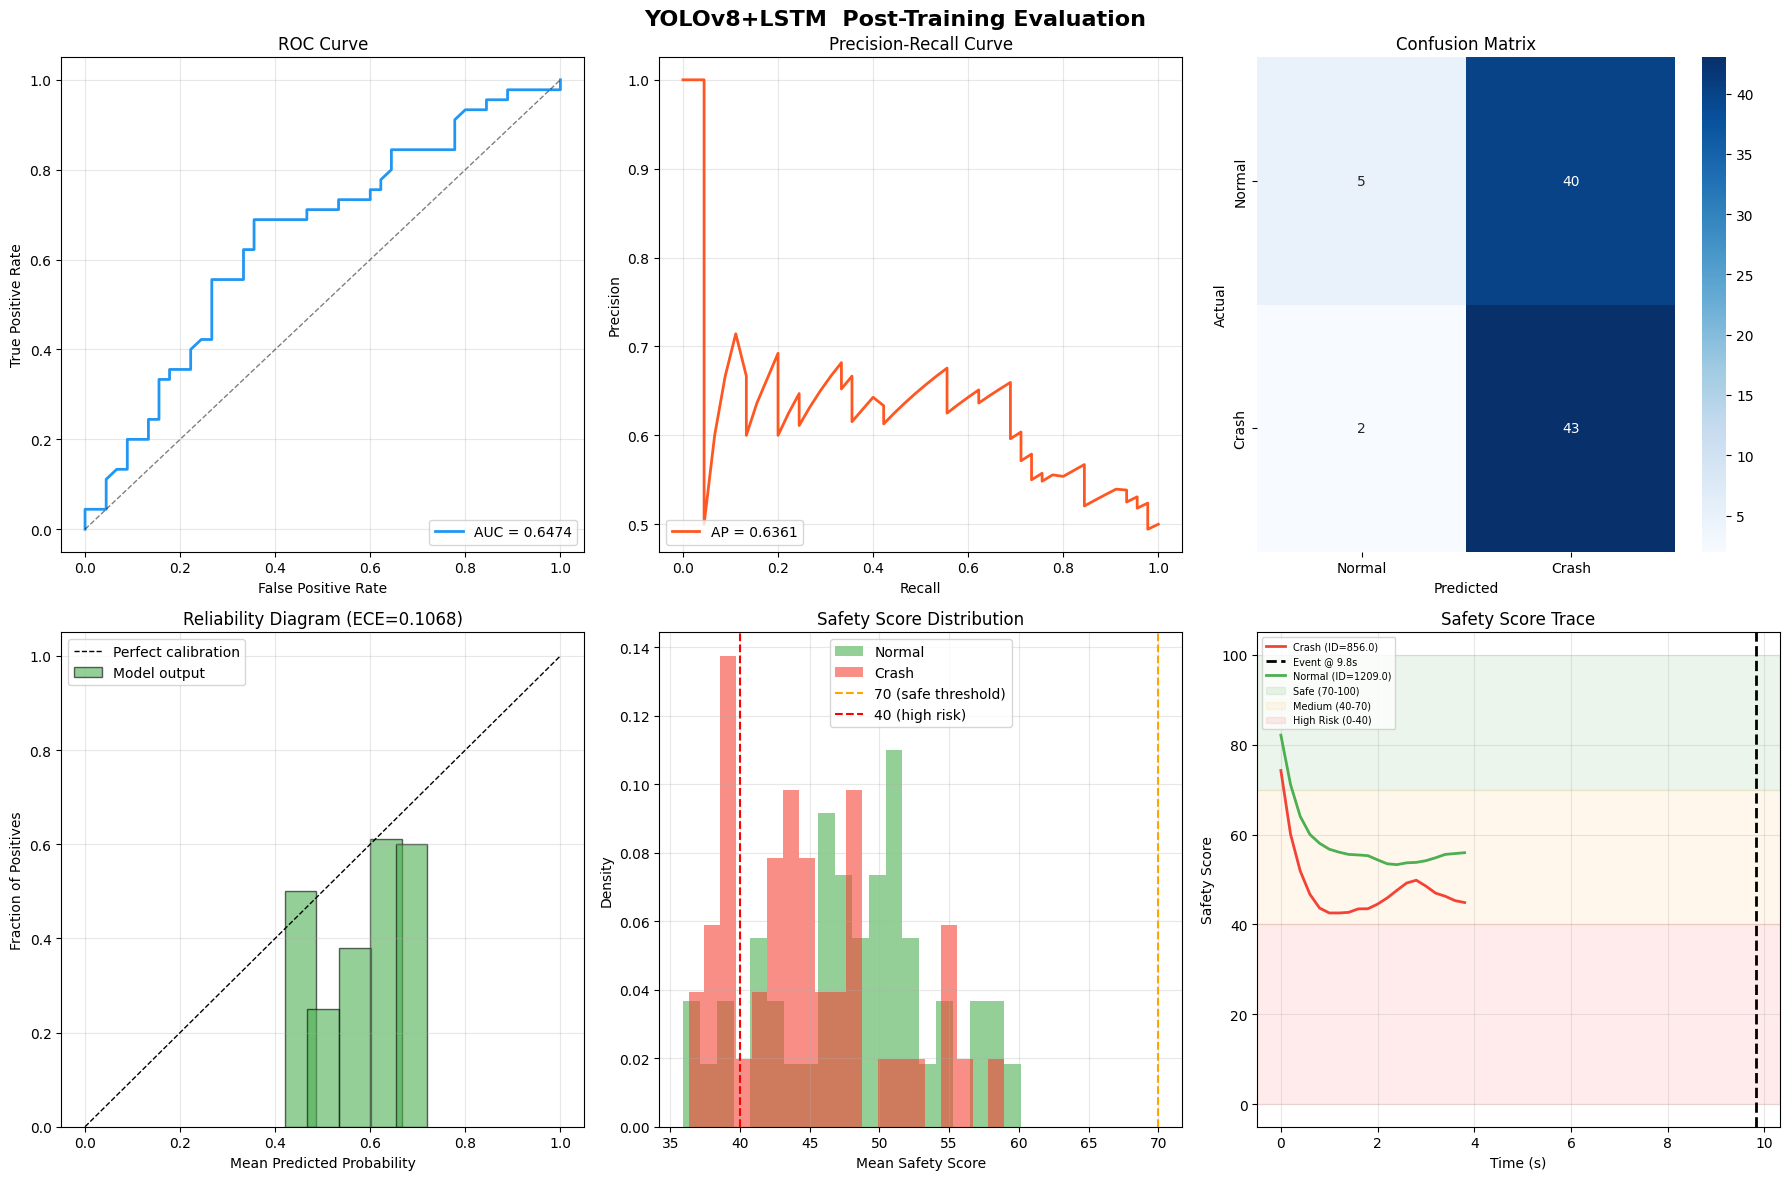

Plots saved: /kaggle/working/results/yolov8_lstm/evaluation_plots.png


In [35]:
y_true = test_labels
y_prob = np.array([fold_predictions[0].get(v, 0.5) for v in test_df['id']])

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
fig.suptitle('YOLOv8+LSTM  Post-Training Evaluation', fontsize=16, fontweight='bold')

# 1. ROC Curve
ax = axes[0, 0]
fpr, tpr, _ = roc_curve(y_true, y_prob)
auc_v = roc_auc_score(y_true, y_prob)
ax.plot(fpr, tpr, color='#2196F3', lw=2, label=f'AUC = {auc_v:.4f}')
ax.plot([0,1],[0,1],'k--',lw=1,alpha=0.5)
ax.set_xlabel('False Positive Rate'); ax.set_ylabel('True Positive Rate')
ax.set_title('ROC Curve'); ax.legend(loc='lower right'); ax.grid(alpha=0.3)

# 2. Precision-Recall Curve
ax = axes[0, 1]
prec, rec, _ = precision_recall_curve(y_true, y_prob)
ap_v = average_precision_score(y_true, y_prob)
ax.plot(rec, prec, color='#FF5722', lw=2, label=f'AP = {ap_v:.4f}')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision')
ax.set_title('Precision-Recall Curve'); ax.legend(loc='lower left'); ax.grid(alpha=0.3)

# 3. Confusion Matrix
ax = axes[0, 2]
y_pred = (y_prob >= 0.5).astype(int)
cm = confusion_matrix(y_true, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
            xticklabels=['Normal','Crash'], yticklabels=['Normal','Crash'])
ax.set_xlabel('Predicted'); ax.set_ylabel('Actual'); ax.set_title('Confusion Matrix')

# 4. Reliability Diagram (Calibration)
ax = axes[1, 0]
ece_b, bin_data = compute_ece(y_true, y_prob, CONFIG['ece_bins'])
bc = [b['avg_confidence'] for b in bin_data if b['count'] > 0]
ba = [b['avg_accuracy']   for b in bin_data if b['count'] > 0]
ax.bar(bc, ba, width=1.0/CONFIG['ece_bins'], alpha=0.6, color='#4CAF50',
       edgecolor='black', label='Model output')
ax.plot([0,1],[0,1],'k--',lw=1,label='Perfect calibration')
ax.set_xlabel('Mean Predicted Probability'); ax.set_ylabel('Fraction of Positives')
ax.set_title(f'Reliability Diagram (ECE={ece_b:.4f})')
ax.legend(); ax.grid(alpha=0.3)

# 5. Safety Score Distribution
ax = axes[1, 1]
if len(safety_results) > 0:
    sdf = pd.DataFrame(safety_results)
    crash_ss  = sdf[sdf['target'] == 1]['mean_safety'].dropna()
    normal_ss = sdf[sdf['target'] == 0]['mean_safety'].dropna()
    ax.hist(normal_ss, bins=20, alpha=0.6, color='#4CAF50', label='Normal', density=True)
    ax.hist(crash_ss,  bins=20, alpha=0.6, color='#F44336', label='Crash',  density=True)
    ax.axvline(70, color='orange', ls='--', lw=1.5, label='70 (safe threshold)')
    ax.axvline(40, color='red',    ls='--', lw=1.5, label='40 (high risk)')
ax.set_xlabel('Mean Safety Score'); ax.set_ylabel('Density')
ax.set_title('Safety Score Distribution'); ax.legend(); ax.grid(alpha=0.3)

# 6. Safety Score Trace
ax = axes[1, 2]
if sample_crash_trace is not None:
    ss  = sample_crash_trace['safety_scores']
    t_ax = np.arange(len(ss)) / CONFIG['sample_fps']
    ax.plot(t_ax, ss, color='#F44336', lw=2, label=f'Crash (ID={sample_crash_trace["video_id"]})')
    toe = sample_crash_trace.get('time_of_event', None)
    if toe:
        try: ax.axvline(float(toe), color='black', ls='--', lw=2, label=f'Event @ {float(toe):.1f}s')
        except ValueError: pass
if sample_normal_trace is not None:
    ss_n = sample_normal_trace['safety_scores']
    t_n  = np.arange(len(ss_n)) / CONFIG['sample_fps']
    ax.plot(t_n, ss_n, color='#4CAF50', lw=2, label=f'Normal (ID={sample_normal_trace["video_id"]})')
ax.axhspan(70,100, alpha=0.08, color='green', label='Safe (70-100)')
ax.axhspan(40, 70, alpha=0.08, color='orange', label='Medium (40-70)')
ax.axhspan( 0, 40, alpha=0.08, color='red',   label='High Risk (0-40)')
ax.set_xlabel('Time (s)'); ax.set_ylabel('Safety Score')
ax.set_title('Safety Score Trace'); ax.legend(fontsize=7); ax.grid(alpha=0.3)
ax.set_ylim(-5, 105)

plt.tight_layout()
plot_path = os.path.join(CONFIG['results_dir'], 'evaluation_plots.png')
plt.savefig(plot_path, dpi=150, bbox_inches='tight')
plt.show(); print(f'Plots saved: {plot_path}')


## 20. Final Summary Table

In [36]:
print(f'\n{"="*80}')
print('YOLOv8+LSTM MODEL  FINAL RESULTS SUMMARY')
print(f'{"="*80}')
print(f'Model: YOLOv8n backbone + DetectionEncoder + LSTM')
print(f'Backbone: {CONFIG["yolo_weights"]} | feat_dim={CONFIG["backbone_feat_dim"]}')
print(f'Detection: max_dets={CONFIG["max_detections"]} | embed={CONFIG["det_embed_dim"]}')
print(f'LSTM: hidden={CONFIG["lstm_hidden_size"]}, layers={CONFIG["lstm_num_layers"]}')
print(f'Input: {CONFIG["sequence_length"]} frames @ {CONFIG["sample_fps"]} FPS = '
      f'{CONFIG["sequence_length"]/CONFIG["sample_fps"]:.1f}s clips')
print(f'Model Size: {size_mb:.2f} MB')
print(f'Parameters: {total_params:,} (trainable: {trainable_params:,})')
print(f'Inference Speed: {fps:.1f} clips/s ({effective_fps:.1f} frames/s)')
print()
print('Cross-Validation Results:')
for r in all_fold_results:
    print(f'  Fold {r["fold"]}: Val AUC={r["best_val_auc"]:.4f}  best_epoch={r["best_epoch"]}')
if all_fold_results:
    aucs = [r['best_val_auc'] for r in all_fold_results]
    ci   = 1.96 * np.std(aucs) / np.sqrt(len(aucs))
    print(f'  Mean: {np.mean(aucs):.4f} +/- {np.std(aucs):.4f}  '
          f'[95% CI: {np.mean(aucs)-ci:.4f}{np.mean(aucs)+ci:.4f}]')
print()
print('Held-Out Test Set (Mean +/- Std, 95% CI):')
print(f'{"Metric":25s} | {"Raw":42s} | {"TTA":42s}')
print('-' * 115)
for mn in ['accuracy','precision','recall','f1','roc_auc','average_precision','fpr_at_95tpr']:
    rv = [m[mn] for m in fold_metrics_raw]
    tv = [m[mn] for m in fold_metrics_tta]
    mr, sr = np.mean(rv), np.std(rv)
    mt, st = np.mean(tv), np.std(tv)
    ci_r = 1.96*sr/np.sqrt(len(rv))
    ci_t = 1.96*st/np.sqrt(len(tv))
    print(f'{mn:25s} | {mr:.4f}+/-{sr:.4f} [{mr-ci_r:.4f},{mr+ci_r:.4f}]  '
          f'| {mt:.4f}+/-{st:.4f} [{mt-ci_t:.4f},{mt+ci_t:.4f}]')
print()
print(f'Calibration (ECE):')
print(f'  Before temp scaling: {np.mean(fold_ece_before):.4f} +/- {np.std(fold_ece_before):.4f}')
print(f'  After  temp scaling: {np.mean(fold_ece_after):.4f} +/- {np.std(fold_ece_after):.4f}')
print(f'  Temperatures: {[f"{t:.3f}" for t in fold_temperatures]}')
print()
if len(safety_results) > 0:
    print(f'Safety Score:')
    sdf = pd.DataFrame(safety_results)
    print(f'  Crash  mean safety: {sdf[sdf["target"]==1]["mean_safety"].mean():.1f}')
    print(f'  Normal mean safety: {sdf[sdf["target"]==0]["mean_safety"].mean():.1f}')
    tta_v = [r for r in sdf[sdf['target']==1]['tta_seconds'].dropna() if r > 0]
    print(f'  TTA: {np.mean(tta_v):.2f}s avg (n={len(tta_v)})' if tta_v else '  TTA: no values')



YOLOv8+LSTM MODEL  FINAL RESULTS SUMMARY
Model: YOLOv8n backbone + DetectionEncoder + LSTM
Backbone: yolov8n.pt | feat_dim=256
Detection: max_dets=20 | embed=128
LSTM: hidden=512, layers=2
Input: 16 frames @ 5 FPS = 3.2s clips
Model Size: 21.70 MB
Parameters: 5,419,922 (trainable: 4,147,266)
Inference Speed: 129.3 clips/s (2068.7 frames/s)

Cross-Validation Results:
  Fold 0: Val AUC=0.7493  best_epoch=1
  Fold 1: Val AUC=0.6537  best_epoch=0
  Fold 2: Val AUC=0.6071  best_epoch=3
  Mean: 0.6700 +/- 0.0592  [95% CI: 0.60310.7370]

Held-Out Test Set (Mean +/- Std, 95% CI):
Metric                    | Raw                                        | TTA                                       
-------------------------------------------------------------------------------------------------------------------
accuracy                  | 0.5556+/-0.0314 [0.5200,0.5911]  | 0.5852+/-0.0409 [0.5389,0.6315]
precision                 | 0.5317+/-0.0189 [0.5103,0.5531]  | 0.5509+/-0.0266 [0.5207,0.5810

In [37]:
# Save results.json for Week 3 statistical analysis
results_out = {
    'model': CONFIG['model_name'],
    'yolo_weights': CONFIG['yolo_weights'],
    'size_mb': size_mb,
    'total_params': total_params,
    'trainable_params': trainable_params,
    'fps': fps,
    'effective_fps': effective_fps,
    'cv_results': all_fold_results,
    'cv_mean_auc': float(np.mean([r['best_val_auc'] for r in all_fold_results])) if all_fold_results else None,
    'cv_std_auc':  float(np.std([r['best_val_auc'] for r in all_fold_results])) if all_fold_results else None,
    'fold_metrics_raw': fold_metrics_raw,
    'fold_metrics_tta': fold_metrics_tta,
    'ece_before': fold_ece_before,
    'ece_after':  fold_ece_after,
    'temperatures': fold_temperatures,
}
with open(os.path.join(CONFIG['results_dir'], 'results.json'), 'w') as f:
    json.dump(results_out, f, indent=2, default=str)
print('results.json saved.')
pd.DataFrame(all_fold_results).to_csv(
    os.path.join(CONFIG['results_dir'], 'cv_scores.csv'), index=False)
print('cv_scores.csv saved.')


results.json saved.
cv_scores.csv saved.


## 21. Streaming Inference Demo

Simulates real-time dashcam inference using a sliding frame buffer. For each incoming frame, if the buffer holds 16 frames, YOLOv8 detection is run on-the-fly (no pre-cached detections needed) and the model produces a live safety score.

This validates the model as a **continuous real-time signal**, not just a clip-level classifier.

In [38]:
class StreamingCrashDetector:
    """
    Real-time streaming crash detector.
    push_frame(frame) -> safety score each time a full 16-frame window is available.
    Runs YOLOv8 detection on each incoming frame for live object features.
    """
    def __init__(self, model, config, device, yolo_det=None):
        self.model  = model; self.model.eval()
        self.config = config; self.device = device
        self.seq_len  = config['sequence_length']
        self.img_size = config['img_size']
        self.K        = config['max_detections']
        self.ema_alpha = config['ema_alpha']
        self.frame_buffer = []  # preprocessed frame tensors
        self.det_buffer   = []  # detection arrays per frame
        self.prev_prob    = config['ema_init']
        self.history      = []
        self.val_t  = get_val_transform(config)
        self.yolo   = yolo_det  # YOLO model for live detection

    def _preprocess(self, frame):
        h = frame.shape[0]; crop_h = int(h * self.config['crop_top_fraction'])
        frame = frame[crop_h:, :, :]
        img   = Image.fromarray(frame).resize((self.img_size, self.img_size), Image.BILINEAR)
        return self.val_t(img)

    def _detect(self, frame_tensor):
        """Run YOLOv8 on a single frame tensor, return (K,6) det array."""
        K = self.K; det = np.zeros((K, 6), np.float32)
        if self.yolo is None: return det
        try:
            # Convert tensor back to PIL for YOLO
            img_np = (frame_tensor.permute(1,2,0).numpy() * 255).clip(0,255).astype(np.uint8)
            res = self.yolo.predict(img_np, verbose=False,
                                    conf=self.config['yolo_conf_threshold'],
                                    iou=self.config['yolo_iou_threshold'])
            if res and res[0].boxes is not None:
                boxes = res[0].boxes
                xy  = boxes.xyxyn.cpu().numpy()
                cf  = boxes.conf.cpu().numpy()
                cl  = boxes.cls.cpu().numpy() / self.config['num_det_classes']
                order = np.argsort(-cf)
                n = min(len(cf), K)
                det[:n, :4] = xy[order[:n]]
                det[:n,  4] = cf[order[:n]]
                det[:n,  5] = cl[order[:n]]
        except Exception: pass
        return det

    @torch.no_grad()
    def push_frame(self, frame):
        t = self._preprocess(frame)
        d = self._detect(t)
        self.frame_buffer.append(t)
        self.det_buffer.append(d)
        if len(self.frame_buffer) > self.seq_len:
            self.frame_buffer.pop(0)
            self.det_buffer.pop(0)
        if len(self.frame_buffer) < self.seq_len:
            return None
        clips = torch.stack(self.frame_buffer).unsqueeze(0).to(self.device)
        det_a = np.stack(self.det_buffer, axis=0)  # (T,K,6)
        det_t = torch.from_numpy(det_a).float().unsqueeze(0).to(self.device)
        mask_t = (det_t[:,:,:,4] > 0)
        with autocast(enabled=self.config['use_amp']):
            logit = self.model(clips, det_t, mask_t)
        raw_p = torch.sigmoid(logit).item()
        smooth_p = self.ema_alpha * raw_p + (1 - self.ema_alpha) * self.prev_prob
        self.prev_prob = smooth_p
        ss = max(0.0, min(100.0, 100.0 - self.config['safety_score_weight'] * smooth_p * 100.0))
        risk = 'HIGH' if ss < 40 else ('MEDIUM' if ss < 70 else 'SAFE')
        entry = {'frame': len(self.history), 'raw_prob': raw_p,
                 'smooth_prob': smooth_p, 'safety_score': ss, 'risk': risk}
        self.history.append(entry)
        return entry

print('StreamingCrashDetector defined.')


StreamingCrashDetector defined.


Loaded fold 0 (AUC=0.7493, epoch=1)
CRASH VIDEO: 856.0 (event @ 9.831s)
  Frame  16: safety=59 [MEDIUM] (p=0.410)
  Frame  24: safety=40 [HIGH] (p=0.602)
  Frame  32: safety=39 [HIGH] (p=0.613)
  Frame  40: safety=42 [MEDIUM] (p=0.581)
  Frame  48: safety=44 [MEDIUM] (p=0.558)
  Frame  56: safety=46 [MEDIUM] (p=0.542)
  Frame  64: safety=50 [MEDIUM] (p=0.501)
  Frame  72: safety=50 [MEDIUM] (p=0.497)
  Frame  80: safety=45 [MEDIUM] (p=0.549)
  Frame  88: safety=44 [MEDIUM] (p=0.559)


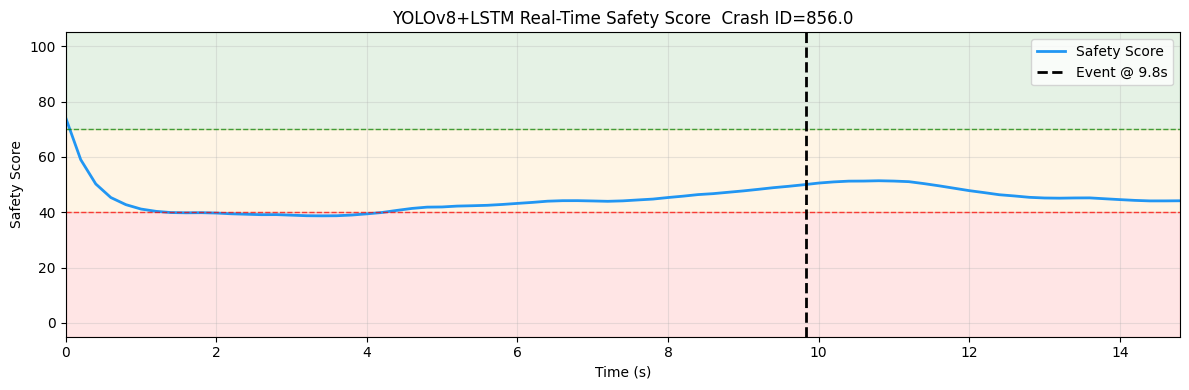


NORMAL VIDEO: 1209.0
  Frame  16: safety=71 [SAFE] (p=0.289)
  Frame  24: safety=54 [MEDIUM] (p=0.463)
  Frame  32: safety=55 [MEDIUM] (p=0.455)
  Frame  40: safety=55 [MEDIUM] (p=0.453)
  Frame  48: safety=54 [MEDIUM] (p=0.456)
  Frame  56: safety=53 [MEDIUM] (p=0.473)
  Frame  64: safety=53 [MEDIUM] (p=0.470)
  Frame  72: safety=54 [MEDIUM] (p=0.459)
  Frame  80: safety=56 [MEDIUM] (p=0.441)
  Frame  88: safety=56 [MEDIUM] (p=0.440)


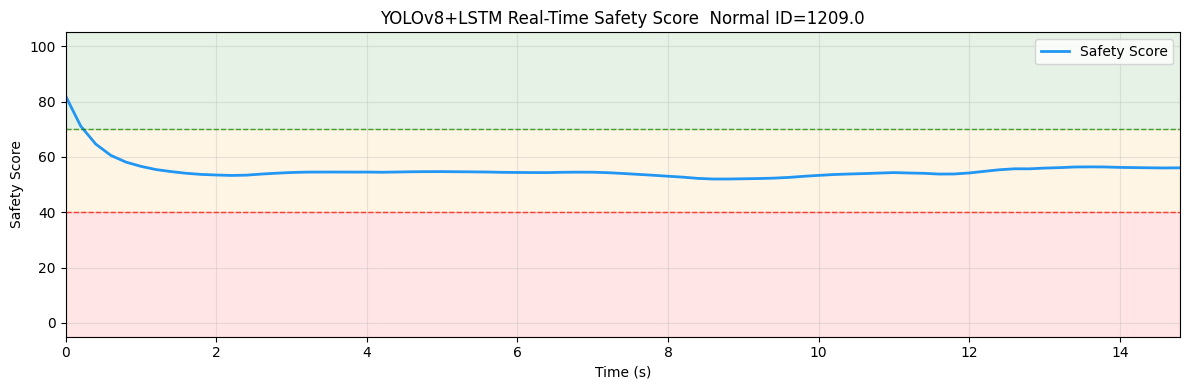


Streaming Demo Summary:
  Crash:  min=39  mean=45  HIGH RISK: 20%
  Normal: min=52  mean=55  HIGH RISK: 0%


In [39]:
def run_streaming_demo(video_path, model, config, device, stride=1, yolo_det=None):
    detector = StreamingCrashDetector(model, config, device, yolo_det)
    try:
        vr = VideoReader(video_path, ctx=cpu(0))
        fps_v = vr.get_avg_fps() or 30.0
        step  = max(1, round(fps_v / config['sample_fps']))
        indices = list(range(0, len(vr), step))
        frames  = vr.get_batch(indices).asnumpy()
        del vr
    except Exception as e:
        print(f'Could not load video: {e}'); return detector
    for i, frame in enumerate(frames[::stride]):
        result = detector.push_frame(frame)
        if result and (i % 8 == 0):
            print(f'  Frame {i:3d}: safety={result["safety_score"]:.0f} '
                  f'[{result["risk"]}] (p={result["smooth_prob"]:.3f})')
    return detector

def plot_streaming_results(detector, title='', time_of_event=None):
    if not detector.history: return
    scores = [h['safety_score'] for h in detector.history]
    t_ax   = np.arange(len(scores)) / CONFIG['sample_fps']
    fig, ax = plt.subplots(figsize=(12, 4))
    ax.plot(t_ax, scores, lw=2, color='#2196F3', label='Safety Score')
    ax.axhspan(70,105, alpha=0.1, color='green')
    ax.axhspan(40, 70, alpha=0.1, color='orange')
    ax.axhspan(-5, 40, alpha=0.1, color='red')
    ax.axhline(70, color='green',  ls='--', lw=1, alpha=0.7)
    ax.axhline(40, color='red',    ls='--', lw=1, alpha=0.7)
    if time_of_event:
        try: ax.axvline(float(time_of_event), color='black', ls='--', lw=2, label=f'Event @ {float(time_of_event):.1f}s')
        except ValueError: pass
    ax.set_xlim(t_ax[0], t_ax[-1])
    ax.set_ylim(-5, 105)
    ax.set_xlabel('Time (s)'); ax.set_ylabel('Safety Score')
    ax.set_title(f'YOLOv8+LSTM Real-Time Safety Score  {title}')
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout(); plt.show()

# Run demo on one crash + one normal video from test set
demo_model = load_best_model(0, CONFIG, DEVICE)
demo_crash  = test_df[test_df['target'] == 1].iloc[0]
demo_normal = test_df[test_df['target'] == 0].iloc[0]

crash_path  = os.path.join(CONFIG['train_video_dir'], f'{int(demo_crash["id"]):05d}.mp4')
normal_path = os.path.join(CONFIG['train_video_dir'], f'{int(demo_normal["id"]):05d}.mp4')

print(f'CRASH VIDEO: {demo_crash["id"]} (event @ {demo_crash.get("time_of_event","?")}s)')
crash_det  = run_streaming_demo(crash_path, demo_model, CONFIG, DEVICE,
                                 yolo_det=yolo_cache_model)
plot_streaming_results(crash_det, title=f'Crash ID={demo_crash["id"]}',
                        time_of_event=demo_crash.get('time_of_event', None))

print(f'\nNORMAL VIDEO: {demo_normal["id"]}')
normal_det = run_streaming_demo(normal_path, demo_model, CONFIG, DEVICE,
                                 yolo_det=yolo_cache_model)
plot_streaming_results(normal_det, title=f'Normal ID={demo_normal["id"]}')

if crash_det.history and normal_det.history:
    cs = [h['safety_score'] for h in crash_det.history]
    ns = [h['safety_score'] for h in normal_det.history]
    print(f'\nStreaming Demo Summary:')
    print(f'  Crash:  min={min(cs):.0f}  mean={np.mean(cs):.0f}  '
          f'HIGH RISK: {sum(1 for s in cs if s<40)/len(cs)*100:.0f}%')
    print(f'  Normal: min={min(ns):.0f}  mean={np.mean(ns):.0f}  '
          f'HIGH RISK: {sum(1 for s in ns if s<40)/len(ns)*100:.0f}%')


In [40]:
del demo_model
torch.cuda.empty_cache()
print('\nYOLOv8+LSTM notebook complete. All results saved to:', CONFIG['results_dir'])
print('Files written:')
for fn in ['config.json','results.json','cv_scores.csv','safety_scores.csv','evaluation_plots.png']:
    p = os.path.join(CONFIG['results_dir'], fn)
    if os.path.exists(p): print(f'  {p}')



YOLOv8+LSTM notebook complete. All results saved to: /kaggle/working/results/yolov8_lstm
Files written:
  /kaggle/working/results/yolov8_lstm/config.json
  /kaggle/working/results/yolov8_lstm/results.json
  /kaggle/working/results/yolov8_lstm/cv_scores.csv
  /kaggle/working/results/yolov8_lstm/safety_scores.csv
  /kaggle/working/results/yolov8_lstm/evaluation_plots.png
